# Dynamical motifs in the Twin latent

Segment each flight's trajectory through the Twin's 64-D shared latent into a small
alphabet of recurring, temporally contiguous **motifs**, then ask whether that alphabet
is anything more than a re-labelling of physical space.

**Method.** The direct generalisation of $k$-means to sequences is a Potts-regularised
objective over each trial,

$$\min_{\mu,\,z}\;\sum_i\sum_t \lVert x_{i,t}-\mu_{z_{i,t}}\rVert^2
  \;+\;\lambda\sum_t \mathbb{1}\!\left[z_{i,t}\neq z_{i,t+1}\right],$$

i.e. Lloyd's algorithm with the assignment step replaced by a Viterbi/DP sweep over the
label sequence — $O(TK)$ per trial with the min-over-states trick, exact given the
centroids, after which the centroids are still just means. Two knobs: $K$ and $\lambda$.
Two trials sharing a label at $t$ may diverge at $t+1$ for a cost of $\lambda$ each, so
"split midway" is free without modelling it explicitly, and a minimum dwell time can be
encoded directly in the DP state to forbid single-frame flicker.

The probabilistic version of the same object is a **Gaussian HMM with a strongly diagonal
Dirichlet prior on the transition rows**, whose Viterbi path is the hard segmentation.
That buys the soft posterior, a proper marginal likelihood for model selection, and
vmapped batching over trials — all of which `dynamax` gives essentially for free.
Both are implemented in `motif_helpers.py`; this notebook runs and compares them.

> **On rSLDS.** `~/Documents/code/linderman/dynamax` does *not* contain a fittable rSLDS —
> its `dynamax.slds` module is Rao–Blackwellised particle *filtering* for an SLDS whose
> parameters are already known, with no EM/Laplace-EM and no recurrent transitions. The
> recurrent SLDS proper lives in the sibling `recurrent-slds/` checkout (Python-2-era
> Cython, on top of `pybasicbayes`/`pyhsmm`). What *is* fully supported in dynamax — and
> is what the description above actually asks for — is the sticky Gaussian HMM, so that
> is what runs here.

## 0. Setup

`dynamax` is imported from the local checkout (it is not pip-installed); its
dependencies (`jax`, `tfp-nightly`, `optax`, `jaxtyping`, `fastprogress`) are installed
in this environment. jax runs on **CPU** here — the fits take seconds, and this keeps it
off the GPU that torch is holding.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sys.path.append(os.path.expanduser('~/Documents/code/utils'))
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))

from digitalbat.utility.utils import set_random_state, parse_bat
import notebook_helpers as nh
import plotting_helpers as ph
import motif_helpers as mh          # <- sticky HMM + Potts k-means machinery

ph.set_pub_style()
MOTIF_DIR = Path('out/motifs'); MOTIF_DIR.mkdir(parents=True, exist_ok=True)
ph.FIG_DIR = Path('out/figures/motifs')

SEED = 1
set_random_state(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
BIN_S = 0.10                      # behaviour/spike bin width, seconds
print('torch device:', device)

torch device: cuda


## 1. Data

Same universe as `figures.ipynb`: the 17 default sessions loaded through
`make_joint_dataloaders`, and the consensus joint encode/decode transformer.

In [2]:
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.datasets.kinematics import make_joint_dataloaders
from digitalbat.models.joint import JointMaskedTransformer

data_config = make_data_config(session_names=list(DEFAULT_SESSION_NAMES))
session_names = data_config['session_names']
dataloaders, _dl_kin, unit_num_dict, meta_info_dict = make_joint_dataloaders(data_config)
behavior_dim = 3

JOINT_CKPT = './out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth'
JOINT_PARAMS = dict(num_layers=4, latent_dim=64, num_heads=4, ff_dim=64, dropout=0.2)


def joint_session_room(s):
    """3-config room map (matches joint-encode-decode.ipynb `session_room`)."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


session_to_room = {s: joint_session_room(s) for s in unit_num_dict}
set_random_state(SEED)
joint_model = JointMaskedTransformer(
    unit_num_dict, behavior_dim=3, input_transform='identity',
    session_to_room=session_to_room, **JOINT_PARAMS).to(device)
joint_model.load_state_dict(torch.load(JOINT_CKPT, map_location=device))
joint_model = joint_model.eval()
print(f'{len(session_names)} sessions | {sum(unit_num_dict.values())} neurons | {JOINT_CKPT}')

  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)


  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)


  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)


  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)


  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)


  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)


  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)


  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)


  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)


17 sessions | 3080 neurons | ./out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth


### Per-flight latent sequences

One record per flight, keeping trials intact (no concatenation across flights — the
whole point is the *within-flight* time course). Both arms of the Twin are taken from
the same neural-token block `x[:, :T]`:

* **encode** pass — behaviour visible, spikes masked (what the model thinks the neurons
  should be doing),
* **decode** pass — spikes visible, behaviour masked.

In [3]:
from notebook_helpers import DIST_THRESH, get_target_locs

SEQ_CACHE = MOTIF_DIR / 'latent_seqs.npy'


@torch.no_grad()
def extract_flight_latents(split):
    """One record per flight: encode/decode latents, position, and metadata."""
    out = []
    for sn in session_names:
        bm = meta_info_dict['behavior_mean'][sn][0, 0, :3]
        bs = meta_info_dict['behavior_std'][sn][0, 0, :3]
        for batch in dataloaders[split][sn]:
            X = batch.behavior.to(device)
            m = batch.mask.to(device)
            B, T, _ = X.shape
            spike0 = X.new_zeros(B, T, unit_num_dict[sn])
            _, _, xf = joint_model(sn, spike0, X, m, m, torch.zeros_like(m))
            h_enc = xf[:, :T].cpu().numpy()
            _, _, xf_d = joint_model(sn, batch.spike.to(device), X, m,
                                     torch.zeros_like(m), m)
            h_dec = xf_d[:, :T].cpu().numpy()
            Xn, mn = batch.behavior.numpy(), batch.mask.numpy() == 1.0
            fpi, fti = batch.flight_path_index.numpy(), batch.flight_type_index.numpy()
            for b in range(B):
                v = mn[b]
                if int(v.sum()) == 0:
                    continue
                pos = (Xn[b, :, :3] * bs + bm)[v]
                out.append(dict(session=sn, split=split, flight_id=int(fpi[b]),
                                cluster=int(fti[b]), bat=parse_bat(sn),
                                enc=h_enc[b, v].astype(np.float32),
                                dec=h_dec[b, v].astype(np.float32),
                                xyz=pos.astype(np.float32)))
    return out


if SEQ_CACHE.exists():
    recs = list(np.load(SEQ_CACHE, allow_pickle=True))
else:
    recs = [r for sp in ('train', 'valid', 'test') for r in extract_flight_latents(sp)]
    for r in recs:                          # endpoint classes -> route id
        rew, perch = get_target_locs(r['session'])
        o = ph.endpoint_class(r['xyz'][0], rew, perch, DIST_THRESH)
        d = ph.endpoint_class(r['xyz'][-1], rew, perch, DIST_THRESH)
        r['origin'], r['dest'], r['route'] = int(o), int(d), int(ph.route_id(o, d))
    np.save(SEQ_CACHE, np.array(recs, dtype=object), allow_pickle=True)

flights = pd.DataFrame([{k: r[k] for k in
                         ('session', 'split', 'flight_id', 'cluster', 'route', 'bat')}
                        for r in recs])
flights['T'] = [len(r['enc']) for r in recs]
split = flights['split'].values
print(flights.groupby('split')['T'].agg(['size', 'min', 'median', 'max']))

       size  min  median  max
split                        
test    278   13    23.0  118
train  1208   11    24.0   98
valid   252   10    23.0  139


## 2. Two segmenters, one objective

**Padding.** Flights run 10–139 bins, and dynamax has no variable-length support, so
`motif_helpers` patches the HMM's E-step: padded steps get zero emission log-likelihood
(making them uninformative, so the forward–backward marginals and `marginal_loglik` at
valid steps are exactly those of the unpadded sequence), and the posterior marginals and
transition pair-marginals are zeroed over the padded tail before sufficient statistics
are collected. This is *exact*, not approximate — verified against per-sequence fits.

**Correspondence.** For a spherical HMM with shared covariance $\sigma^2 I$ and a
transition matrix with $p_\text{stay}$ on the diagonal, Viterbi minimises the Potts
objective with

$$\lambda = 2\sigma^2\log\frac{p_\text{stay}}{p_\text{switch}},$$

which is what `mh.lambda_from_hmm` reports. It is an identity only under a shared
spherical covariance, so read it as the scale the two knobs share.

**Preprocessing.** z-score each latent dimension, then PCA — both fitted on **train**
flights only. No whitening (it inflates directions the model barely uses). 15 PCs
capture ~65% of the latent variance; with full per-state covariances that is ~120
parameters per state against ~37k training timepoints.

In [4]:
N_PCS, K, STICKINESS = 15, 2, 100.0      # K set in §3 by the stability sweep


def make_projector(arm):
    """z-score + PCA fitted on TRAIN flights only."""
    tr = np.flatnonzero(split == 'train')
    Z = np.concatenate([recs[i][arm] for i in tr])
    mu, sd = Z.mean(0), Z.std(0)
    Zc = (Z - mu) / sd
    ctr = Zc.mean(0)
    comps = np.linalg.svd(Zc - ctr, full_matrices=False)[2][:N_PCS]
    return lambda a: ((a - mu) / sd - ctr) @ comps.T


def stacked(project, arm='enc'):
    """{split: (Y (N, T_max, D), mask (N, T_max))}."""
    return {s: mh.stack_sequences([project(recs[i][arm]) for i in np.flatnonzero(split == s)])
            for s in ('train', 'valid', 'test')}


def trim(z, mask):
    """Padded label matrix -> list of per-flight paths."""
    return [zz[:int(m.sum())] for zz, m in zip(z, mask)]


project_enc = make_projector('enc')
data = stacked(project_enc)
for s, (Y, M) in data.items():
    print(f'{s:6s} {Y.shape}  {int(M.sum())} valid timepoints')

train  (1208, 98, 15)  36984 valid timepoints
valid  (252, 139, 15)  7222 valid timepoints
test   (278, 118, 15)  8072 valid timepoints


In [5]:
# --- sticky Gaussian HMM (dynamax) --------------------------------------------
hmm, params, lps = mh.fit_sticky_hmm(*data['train'], K, stickiness=STICKINESS,
                                     num_iters=60, num_restarts=3, seed=0)
Yt, Mt = data['test']
paths = trim(hmm.batch_most_likely_states(params, Yt, Mt), Mt)
lam_hat = mh.lambda_from_hmm(params)
mean_dwell = np.mean([d for p in paths for _, d in mh.run_length_encode(p)])
print(f'sticky HMM  K={K}  implied Potts lambda={lam_hat:.1f}  '
      f'mean dwell={mean_dwell:.2f} bins ({mean_dwell*BIN_S:.2f} s)')

# --- Potts k-means at the same lambda (hard-assignment limit) ------------------
Ytr, Mtr = data['train']
_, centroids, _ = mh.potts_kmeans(Ytr, Mtr, K, lam_hat, min_dwell=1,
                                  num_iters=25, num_restarts=3, seed=0)
cost = ((Yt[:, :, None, :] - centroids[None, None]) ** 2).sum(-1)
paths_potts = trim(mh.potts_viterbi(cost, Mt, lam_hat, min_dwell=1)[0], Mt)
_, agree = mh.match_states(np.concatenate(paths), np.concatenate(paths_potts), K)
print(f'Potts k-means agrees with the HMM on {agree:.1%} of frames (chance {1/K:.1%})')

# --- the min-dwell knob, encoded directly in the DP state ---------------------
for m_dwell in (1, 3, 5):
    _, cen, _ = mh.potts_kmeans(Ytr, Mtr, K, lam_hat, min_dwell=m_dwell,
                                num_iters=25, num_restarts=1, seed=0)
    c = ((Yt[:, :, None, :] - cen[None, None]) ** 2).sum(-1)
    pp = trim(mh.potts_viterbi(c, Mt, lam_hat, min_dwell=m_dwell)[0], Mt)
    interior = [d for p in pp for _, d in mh.run_length_encode(p)[:-1]]
    print(f'  min_dwell={m_dwell}: shortest interior run = {min(interior)} bins, '
          f'mean dwell = {np.mean([d for p in pp for _, d in mh.run_length_encode(p)]):.2f}')

sticky HMM  K=2  implied Potts lambda=18.1  mean dwell=16.21 bins (1.62 s)


Potts k-means agrees with the HMM on 68.5% of frames (chance 50.0%)


  min_dwell=1: shortest interior run = 2 bins, mean dwell = 19.78


  min_dwell=3: shortest interior run = 3 bins, mean dwell = 19.78


  min_dwell=5: shortest interior run = 5 bins, mean dwell = 20.33


## 3. Choosing $K$, $\kappa$ and $\lambda$

Three sweeps, all fitted on **train** and selected on **valid**; the test split is only
ever segmented, never used to choose anything.

The honest result is in the first two panels: **held-out marginal likelihood is monotone
in $K$** out to $K=60$ and gives no elbow. That is expected — a smoothly varying latent
trajectory is a tiling problem, not a mixture with a true component count, so more
Gaussians always fit better. What *does* identify a $K$ is **stability**: fit on two
disjoint halves of the training flights, Viterbi both on test, Hungarian-match the
labels, and measure frame agreement. That peaks at $K \approx 6$–$8$ and degrades above
it. $K=8$ maximises agreement-above-chance and is what the rest of the notebook uses.

In [6]:
def sweep_or_load(name, fn):
    f = MOTIF_DIR / f'sweep_{name}.csv'
    if f.exists():
        return pd.read_csv(f)
    df = pd.DataFrame(fn())
    df.to_csv(f, index=False)
    return df


def _stability():
    rng = np.random.default_rng(0)
    tr_n = data['train'][0].shape[0]
    perm = rng.permutation(tr_n); halves = (perm[:tr_n // 2], perm[tr_n // 2:])
    Yv, Mv = data['valid']
    rows = []
    for k in [4, 6, 8, 10, 12, 15, 20, 25, 30, 40, 60]:
        zs = []
        for h in halves:
            hm, pr, _ = mh.fit_sticky_hmm(Ytr[h], Mtr[h], k, stickiness=STICKINESS,
                                          num_iters=60, num_restarts=2, seed=0)
            zs.append(hm.batch_most_likely_states(pr, Yt, Mt)[Mt > 0])
        _, ag = mh.match_states(zs[0], zs[1], k)
        hm, pr, _ = mh.fit_sticky_hmm(Ytr, Mtr, k, stickiness=STICKINESS,
                                      num_iters=60, num_restarts=2, seed=0)
        pp = trim(hm.batch_most_likely_states(pr, Yt, Mt), Mt)
        rows.append(dict(K=k, split_half_agreement=ag, chance=1 / k,
                         valid_ll=float(hm.batch_marginal_log_prob(pr, Yv, Mv).sum() / Mv.sum()),
                         runs_per_flight=np.mean([len(mh.run_length_encode(p)) for p in pp]),
                         mean_dwell=np.mean([d for p in pp for _, d in mh.run_length_encode(p)])))
        print(rows[-1], flush=True)
    return rows


def _stickiness():
    Yv, Mv = data['valid']
    rows = []
    for kappa in [0.0, 1e3, 1e4, 3e4, 1e5, 3e5, 1e6]:
        hm, pr, _ = mh.fit_sticky_hmm(Ytr, Mtr, 12, stickiness=kappa, num_iters=60,
                                      num_restarts=2, seed=0)
        pp = trim(hm.batch_most_likely_states(pr, Yt, Mt), Mt)
        A = np.asarray(pr.transitions.transition_matrix)
        rows.append(dict(stickiness=kappa, p_stay=float(np.mean(np.diag(A))),
                         valid_ll=float(hm.batch_marginal_log_prob(pr, Yv, Mv).sum() / Mv.sum()),
                         mean_dwell=np.mean([d for p in pp for _, d in mh.run_length_encode(p)]),
                         lam=mh.lambda_from_hmm(pr)))
        print(rows[-1], flush=True)
    return rows


def _potts():
    rows = []
    for lam in [0., 2., 5., 10., 15., 20., 40., 80.]:
        _, cen, obj = mh.potts_kmeans(Ytr, Mtr, 12, lam, num_iters=25, num_restarts=2, seed=0)
        c = ((Yt[:, :, None, :] - cen[None, None]) ** 2).sum(-1)
        pp = trim(mh.potts_viterbi(c, Mt, lam)[0], Mt)
        rows.append(dict(lam=lam, obj=obj,
                         mean_dwell=np.mean([d for p in pp for _, d in mh.run_length_encode(p)]),
                         runs_per_flight=np.mean([len(mh.run_length_encode(p)) for p in pp])))
        print(rows[-1], flush=True)
    return rows


st = sweep_or_load('stability', _stability)
sk = sweep_or_load('stickiness', _stickiness)
pt = sweep_or_load('potts', _potts)
st.round(3)

,K,split_half_agreement,chance,valid_ll,runs_per_flight,mean_dwell
0,4,0.647,0.250,-21.837,2.914,9.965
1,6,0.821,0.167,-19.660,3.299,8.803
2,8,0.796,0.125,-18.549,3.903,7.440
3,10,0.595,0.100,-17.774,4.306,6.744
4,12,0.723,0.083,-16.645,4.108,7.068
5,15,0.570,0.067,-15.880,4.385,6.622
6,20,0.658,0.050,-14.621,4.835,6.006
7,25,0.598,0.040,-13.502,4.651,6.243
8,30,0.595,0.033,-12.548,5.022,5.782
9,40,0.594,0.025,-11.318,5.147,5.641


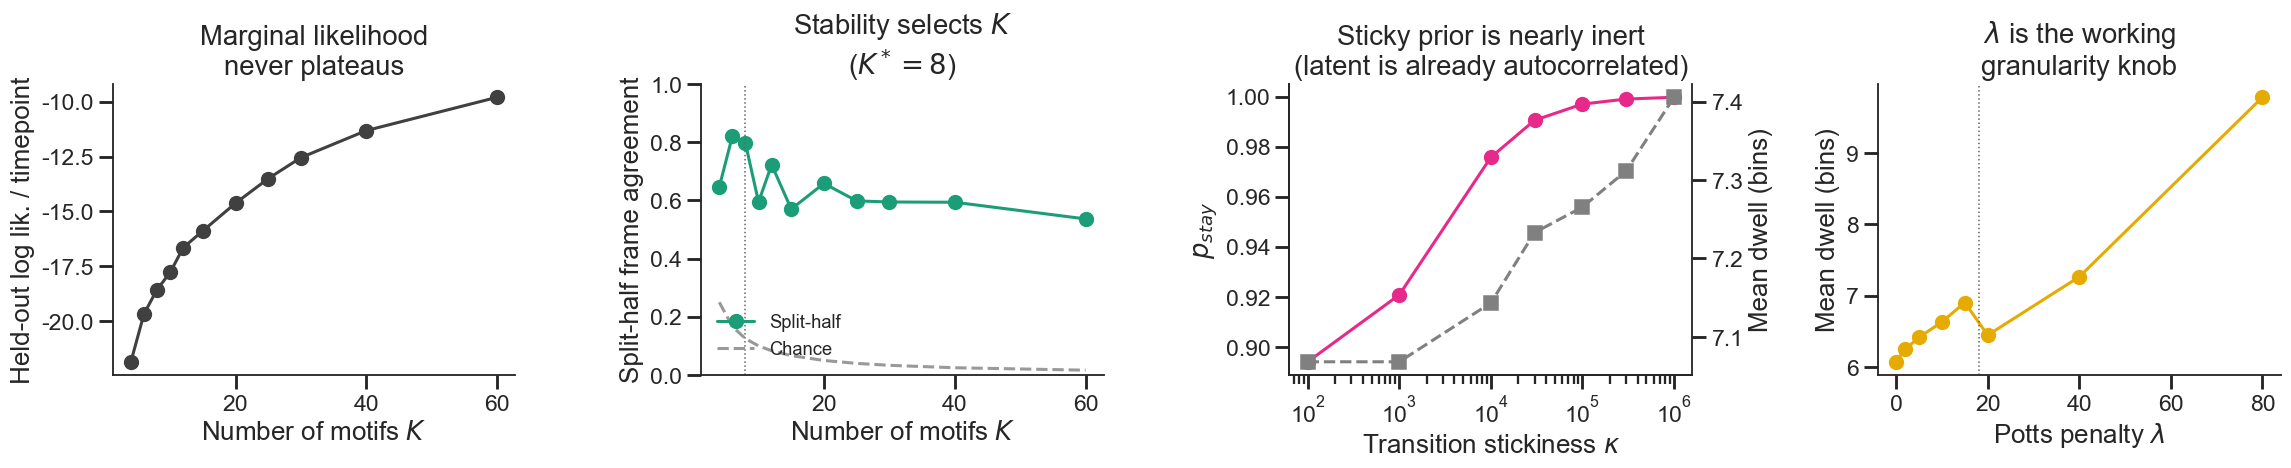

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))

ax = axes[0]
ax.plot(st['K'], st['valid_ll'], 'o-', color='0.25')
ax.set(xlabel='number of motifs $K$', ylabel='held-out log lik. / timepoint',
       title='Marginal likelihood\nnever plateaus')

ax = axes[1]
ax.plot(st['K'], st['split_half_agreement'], 'o-', color=sns.color_palette('Dark2')[0],
        label='split-half')
ax.plot(st['K'], st['chance'], '--', color='0.6', label='chance')
kbest = int(st.loc[(st['split_half_agreement'] - st['chance']).idxmax(), 'K'])
ax.axvline(kbest, color='0.4', lw=1, ls=':')
ax.set(xlabel='number of motifs $K$', ylabel='split-half frame agreement', ylim=(0, 1),
       title=f'Stability selects $K$\n($K^*={kbest}$)')
ax.legend(frameon=False, fontsize=12, loc='lower left')

ax = axes[2]
ax.semilogx(np.maximum(sk['stickiness'], 1e2), sk['p_stay'], 'o-',
            color=sns.color_palette('Dark2')[3])
ax2 = ax.twinx()
ax2.semilogx(np.maximum(sk['stickiness'], 1e2), sk['mean_dwell'], 's--', color='0.5')
ax2.set_ylabel('mean dwell (bins)', fontsize=17)
ax2.spines['right'].set_visible(True)
ax.set(xlabel='transition stickiness $\\kappa$', ylabel='$p_{stay}$',
       title='Sticky prior is nearly inert\n(latent is already autocorrelated)')

ax = axes[3]
ax.plot(pt['lam'], pt['mean_dwell'], 'o-', color=sns.color_palette('Dark2')[5])
ax.axvline(lam_hat, color='0.4', ls=':', lw=1)
ax.set(xlabel='Potts penalty $\\lambda$', ylabel='mean dwell (bins)',
       title='$\\lambda$ is the working\ngranularity knob')

for a in fig.axes:
    a.tick_params(labelsize=15)
fig.tight_layout()
ph.save_fig(fig, 'motif_model_selection')
plt.show()

## 4. What the motifs are

Anatomy of the $K=8$ alphabet on the held-out flights: how often each motif is used, how
long it lasts, how many of the 17 sessions and 6 bats use it, and which motif tends to
follow which (self-transitions excluded, so each row is the distribution over the *next
different* motif — the "grammar").

The headline here is the third panel: **every motif is used by all 17 sessions and all 6
bats**, even though the rooms differ physically. The alphabet is shared, not per-animal.

In [8]:
test_idx = np.flatnonzero(split == 'test')
tf = flights.iloc[test_idx].reset_index(drop=True)
xyz = [recs[i]['xyz'] for i in test_idx]
speed = [np.r_[0, np.linalg.norm(np.diff(p, axis=0), axis=1) / BIN_S] for p in xyz]
MOTIF_PAL = dict(zip(range(K), sns.color_palette('tab20', K)))

occ = np.bincount(np.concatenate(paths), minlength=K) / sum(len(p) for p in paths)
dw = mh.dwell_times(paths, K)
n_sess = [len({tf['session'][j] for j, p in enumerate(paths) if (p == k).any()}) for k in range(K)]
n_bats = [len({tf['bat'][j] for j, p in enumerate(paths) if (p == k).any()}) for k in range(K)]
motif_tab = pd.DataFrame(dict(
    motif=range(K), occupancy=occ,
    median_dwell_s=[np.median(dw[k]) * BIN_S if len(dw[k]) else np.nan for k in range(K)],
    speed=mh.state_profile(paths, [s[:, None] for s in speed], K)[:, 0],
    n_sessions=n_sess, n_bats=n_bats))
motif_tab.round(3)

,motif,occupancy,median_dwell_s,speed,n_sessions,n_bats
0,0,0.561,1.95,2.612,17,6
1,1,0.439,1.80,2.792,17,6


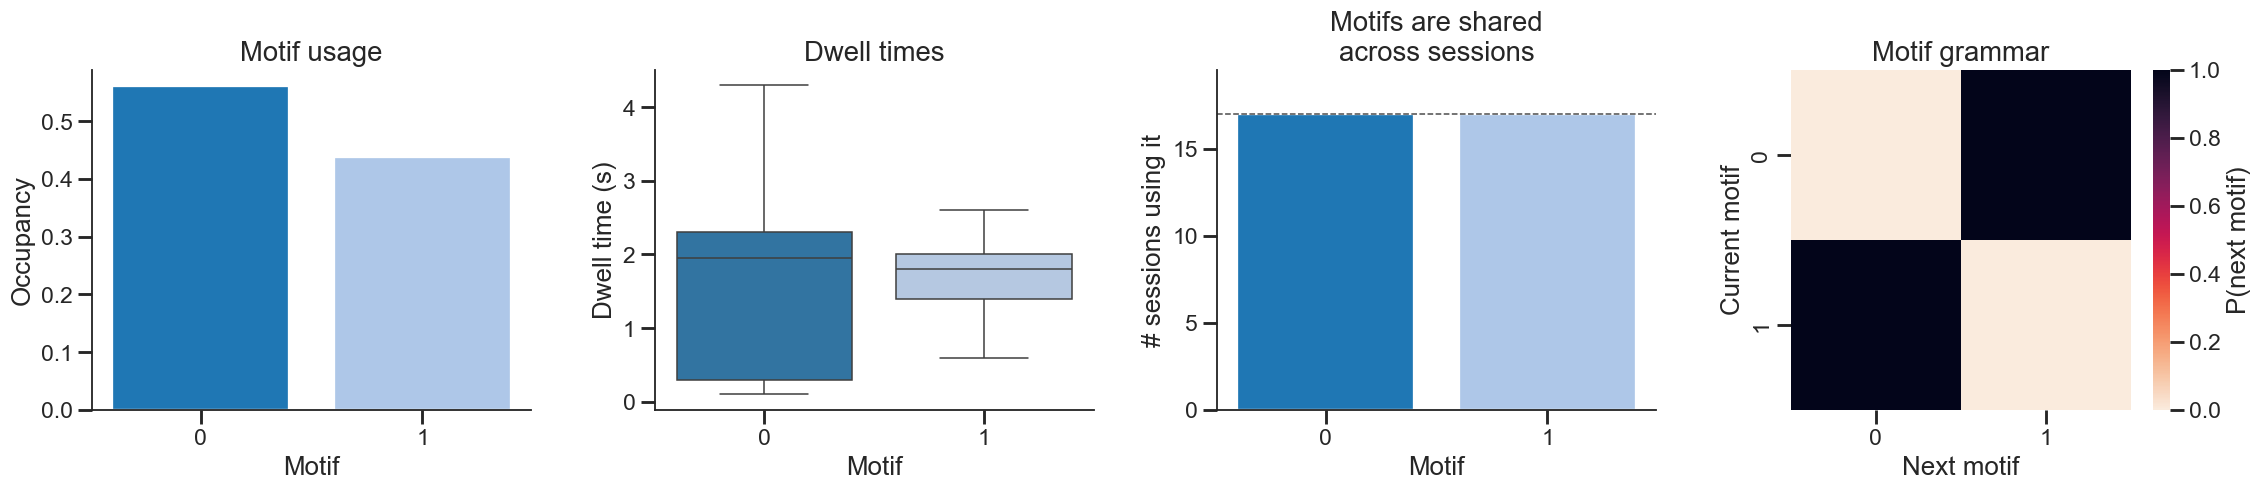

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))

ax = axes[0]
ax.bar(range(K), occ, color=[MOTIF_PAL[k] for k in range(K)])
ax.set(xlabel='motif', ylabel='occupancy', xticks=range(K), title='Motif usage')

ax = axes[1]
dd = pd.DataFrame([{'motif': k, 'dwell': d * BIN_S} for k in range(K) for d in dw[k]])
ph.cat_boxplot(ax, dd, 'motif', 'dwell', list(range(K)), MOTIF_PAL)
ax.set(xlabel='motif', ylabel='dwell time (s)', title='Dwell times')

ax = axes[2]
ax.bar(range(K), n_sess, color=[MOTIF_PAL[k] for k in range(K)])
ax.axhline(tf['session'].nunique(), color='0.3', ls='--', lw=1)
ax.set(xlabel='motif', ylabel='# sessions using it', xticks=range(K),
       ylim=(0, tf['session'].nunique() * 1.15),
       title='Motifs are shared\nacross sessions')

ax = axes[3]
C = mh.transition_counts(paths, K)
sns.heatmap(C / np.maximum(C.sum(1, keepdims=True), 1), ax=ax, cmap='rocket_r',
            square=True, cbar_kws=dict(label='P(next motif)'))
ax.set(xlabel='next motif', ylabel='current motif', title='Motif grammar')

for a in fig.axes:
    a.tick_params(labelsize=15)
fig.tight_layout()
ph.save_fig(fig, 'motif_anatomy')
plt.show()

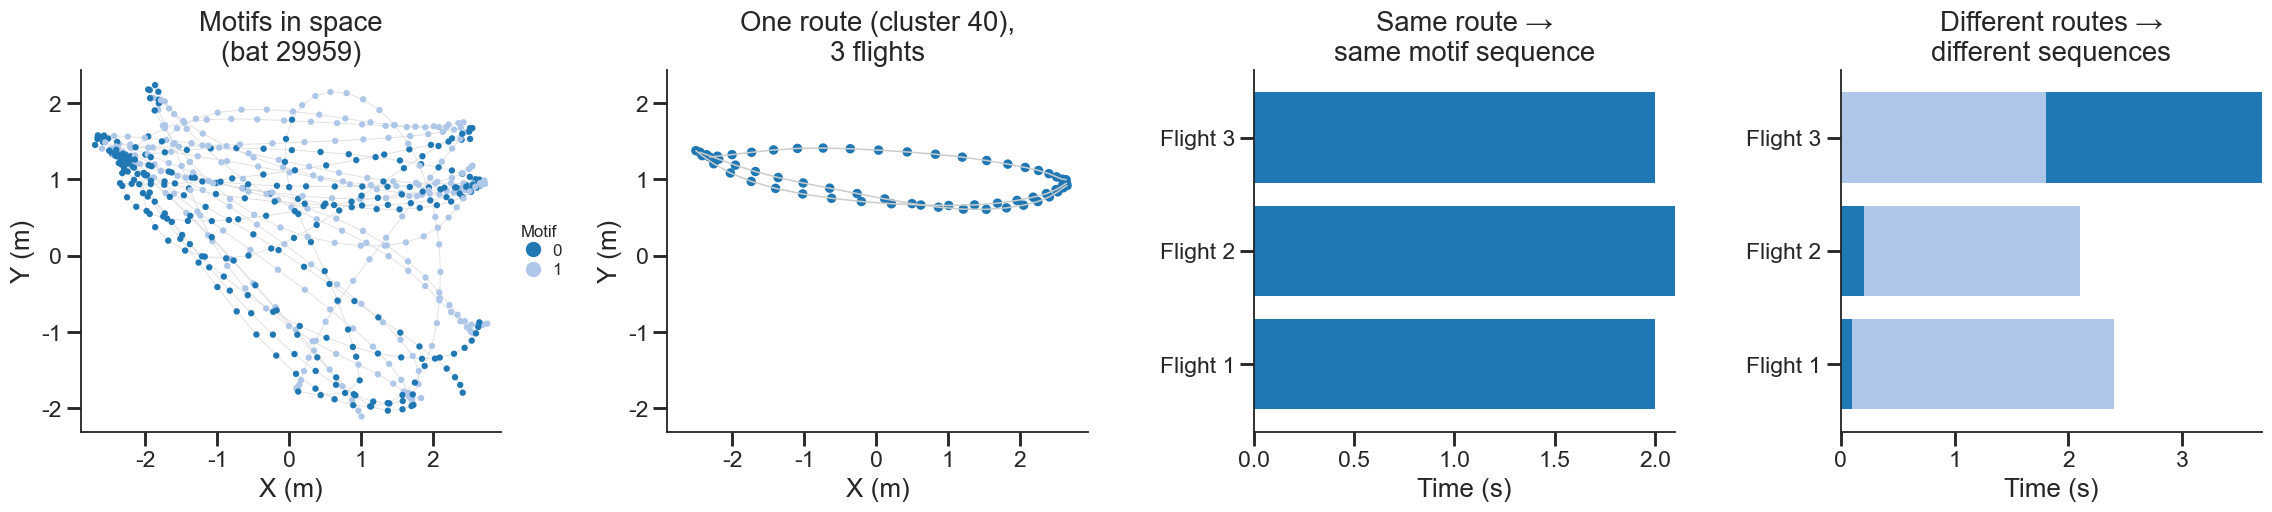

In [10]:
# Motifs painted onto physical space, and motif ribbons for individual flights.
sess = tf['session'].value_counts().index[0]
sel = np.flatnonzero(tf['session'].values == sess)
top = tf.iloc[sel]['cluster'].value_counts().index[0]
same = [j for j in sel if tf['cluster'][j] == top][:3]
rng = np.random.default_rng(0)
diff = rng.choice([j for j in sel if tf['cluster'][j] != top], 3, replace=False)

fig, axes = plt.subplots(1, 4, figsize=(21, 5.0))
P = np.concatenate([xyz[j] for j in sel]); Zl = np.concatenate([paths[j] for j in sel])
xlim = (P[:, 0].min() - .2, P[:, 0].max() + .2)
ylim = (P[:, 1].min() - .2, P[:, 1].max() + .2)

ax = axes[0]
for j in sel:
    ax.plot(xyz[j][:, 0], xyz[j][:, 1], color='0.88', lw=0.6, zorder=1)
ax.scatter(P[:, 0], P[:, 1], c=[MOTIF_PAL[k] for k in Zl], s=7, zorder=2)
ax.set(xlabel='x (m)', ylabel='y (m)', xlim=xlim, ylim=ylim,
       title=f'Motifs in space\n(bat {ph.bat_of(sess)})')

ax = axes[1]
for j in same:
    ax.plot(xyz[j][:, 0], xyz[j][:, 1], color='0.8', lw=1)
    ax.scatter(xyz[j][:, 0], xyz[j][:, 1], c=[MOTIF_PAL[k] for k in paths[j]], s=22)
ax.set(xlabel='x (m)', ylabel='y (m)', xlim=xlim, ylim=ylim,
       title=f'One route (cluster {top}),\n{len(same)} flights')

for ax, group, ttl in [(axes[2], same, 'Same route →\nsame motif sequence'),
                       (axes[3], diff, 'Different routes →\ndifferent sequences')]:
    for r, j in enumerate(group):
        for t, k in enumerate(paths[j]):
            ax.add_patch(plt.Rectangle((t * BIN_S, r - .4), BIN_S, .8,
                                       color=MOTIF_PAL[int(k)], lw=0))
    ax.set(xlim=(0, max(len(paths[j]) for j in group) * BIN_S), ylim=(-.6, len(group) - .4),
           xlabel='time (s)', yticks=range(len(group)),
           yticklabels=[f'flight {i + 1}' for i in range(len(group))], title=ttl)

axes[0].legend(handles=[plt.Line2D([], [], marker='o', ls='', color=MOTIF_PAL[k],
                                   label=str(k)) for k in range(K)],
               title='motif', frameon=False, fontsize=11, title_fontsize=11,
               loc='center left', bbox_to_anchor=(1.0, .5), handletextpad=.1,
               labelspacing=.25)
for a in fig.axes:
    a.tick_params(labelsize=15)
fig.tight_layout()
ph.save_fig(fig, 'motif_space_examples')
plt.show()

## 5. Are the motifs more than position bins?

The latent is largely position-driven, so a motif alphabet that merely tiles the room
would be uninteresting. Four tests, each against a **matched control**: the identical
pipeline (same $K$, same stickiness, same EM settings) run on the raw 3-D **position**
trajectories instead of the latent. The two segmentations land at comparable granularity
(≈3.9 vs ≈4.2 motif runs per flight), so normalised edit distances are comparable.

1. **Reproducibility** — within- vs between-route edit distance between motif orders,
   permuting route labels *within session* so session identity cannot manufacture it.
2. **Position sufficiency** — a kNN trying to predict the motif label from 3-D position
   alone, cross-validated across held-out *flights* within each session.
3. **Route information at matched location** — $I(\text{motif};\text{route}\mid\text{spatial bin})$,
   with the null built by permuting route labels across flights within session (flight-level,
   because timepoints within a flight are not independent).
4. **Arm agreement** — independently fitted encode-arm and decode-arm segmentations,
   Hungarian-matched.

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GroupKFold
from scipy.stats import wilcoxon


def segment(project, arm, k=K):
    d = stacked(project, arm)
    hm, pr, _ = mh.fit_sticky_hmm(*d['train'], k, stickiness=STICKINESS,
                                  num_iters=60, num_restarts=3, seed=0)
    Y, M = d['test']
    return trim(hm.batch_most_likely_states(pr, Y, M), M)


paths_dec = segment(make_projector('dec'), 'dec')
X0 = np.concatenate([recs[i]['xyz'] for i in np.flatnonzero(split == 'train')])
mx, sx = X0.mean(0), X0.std(0)
paths_pos = segment(lambda a: (a - mx) / sx, 'xyz')
SPACES = [('latent', paths), ('position', paths_pos)]
for name, pp in SPACES:
    print(f'{name:9s} runs/flight {np.mean([len(mh.run_length_encode(p)) for p in pp]):.2f}')

latent    runs/flight 1.79
position  runs/flight 2.14


In [12]:
print('--- A. same route -> same motif order --------------------------------')
rep = {}
for name, pp in SPACES:
    ms = [mh.motif_string(p) for p in pp]
    for lab, g in [('route', tf['route'].values), ('cluster', tf['cluster'].values)]:
        rep[(name, lab)] = r = mh.grouped_sequence_distance(
            ms, g, blocks=tf['session'].values, n_perm=1000, seed=0)
        print(f'  {name:8s} {lab:8s} within={r["within"]:.3f} between={r["between"]:.3f} '
              f'diff={r["diff"]:+.3f} p={r["p"]:.4f}')

print('\n--- B. does position alone explain the motif label? ------------------')
knn = {}
for name, pp in SPACES:
    accs = []
    for s in tf['session'].unique():
        j = np.flatnonzero(tf['session'].values == s)
        Xs = np.concatenate([xyz[i] for i in j])
        ys = np.concatenate([pp[i] for i in j])
        gr = np.concatenate([np.full(len(pp[i]), i) for i in j])
        if len(np.unique(ys)) < 2 or len(j) < 6:
            continue
        pred = np.empty_like(ys)
        for a, b in GroupKFold(5).split(Xs, ys, gr):
            pred[b] = KNeighborsClassifier(15).fit(Xs[a], ys[a]).predict(Xs[b])
        accs.append((pred == ys).mean())
    knn[name] = np.array(accs)
    print(f'  {name:8s} kNN(position -> motif) = {np.mean(accs):.3f} +/- {np.std(accs):.3f}')
p_knn = wilcoxon(knn['latent'], knn['position']).pvalue
print(f'  paired Wilcoxon across {len(knn["latent"])} sessions: p = {p_knn:.2e}')


def cond_mi(pp, nbins=6, n_perm=300, seed=0):
    """I(motif; route | spatial bin), with a flight-level within-session null."""
    rng = np.random.default_rng(seed)
    obs, nulls = [], []
    for s in tf['session'].unique():
        j = np.flatnonzero(tf['session'].values == s)
        if len(j) < 10:
            continue
        P = np.concatenate([xyz[i] for i in j])
        Zl = np.concatenate([pp[i] for i in j])
        fl = np.concatenate([np.full(len(pp[i]), i) for i in j])
        ed = [np.quantile(P[:, d], np.linspace(0, 1, nbins + 1)[1:-1]) for d in range(3)]
        b = sum(np.digitize(P[:, d], ed[d]) * (nbins ** d) for d in range(3))

        def mi(route_by_flight):
            rv = route_by_flight[fl]
            tot = 0.0
            for bb in np.unique(b):
                m = b == bb
                if m.sum() < 20:
                    continue
                zz, rr = Zl[m], rv[m]
                if len(np.unique(zz)) < 2 or len(np.unique(rr)) < 2:
                    continue
                jt = np.histogram2d(zz, rr, bins=[np.r_[np.unique(zz), 1e9],
                                                  np.r_[np.unique(rr), 1e9]])[0]
                jt /= jt.sum()
                px, py = jt.sum(1, keepdims=True), jt.sum(0, keepdims=True)
                with np.errstate(divide='ignore', invalid='ignore'):
                    t = jt * np.log2(jt / (px * py))
                    t[~np.isfinite(t)] = 0
                tot += m.sum() / len(b) * t.sum()
            return tot

        base = tf['route'].values.copy()
        obs.append(mi(base))
        nl = []
        for _ in range(n_perm):
            g = base.copy(); g[j] = rng.permutation(g[j]); nl.append(mi(g))
        nulls.append(nl)
    obs, nl = np.array(obs), np.array(nulls)
    return obs, nl, (1 + np.sum(nl.mean(0) >= obs.mean())) / (nl.shape[1] + 1)


print('\n--- C. I(motif; route | spatial bin) ---------------------------------')
mi_res = {}
for name, pp in SPACES:
    o, n, p = mi_res[name] = cond_mi(pp)
    print(f'  {name:8s} {o.mean():.4f} bits  (null {n.mean():.4f}, p = {p:.4f})')

print('\n--- D. encode vs decode arm -----------------------------------------')
_, agree_ed = mh.match_states(np.concatenate(paths), np.concatenate(paths_dec), K)
print(f'  Hungarian-matched frame agreement = {agree_ed:.3f} (chance {1/K:.3f})')

--- A. same route -> same motif order --------------------------------
  latent   route    within=0.065 between=0.430 diff=+0.364 p=0.0010


  latent   cluster  within=0.013 between=0.373 diff=+0.360 p=0.0010
  position route    within=0.074 between=0.621 diff=+0.547 p=0.0010


  position cluster  within=0.000 between=0.535 diff=+0.535 p=0.0010

--- B. does position alone explain the motif label? ------------------
  latent   kNN(position -> motif) = 0.665 +/- 0.089
  position kNN(position -> motif) = 0.979 +/- 0.010
  paired Wilcoxon across 17 sessions: p = 1.53e-05

--- C. I(motif; route | spatial bin) ---------------------------------


  latent   0.0622 bits  (null 0.0213, p = 0.0033)


  position 0.0012 bits  (null 0.0010, p = 0.2890)

--- D. encode vs decode arm -----------------------------------------
  Hungarian-matched frame agreement = 0.661 (chance 0.500)


/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:837: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  setter([_cap_first(l) for l in labs])


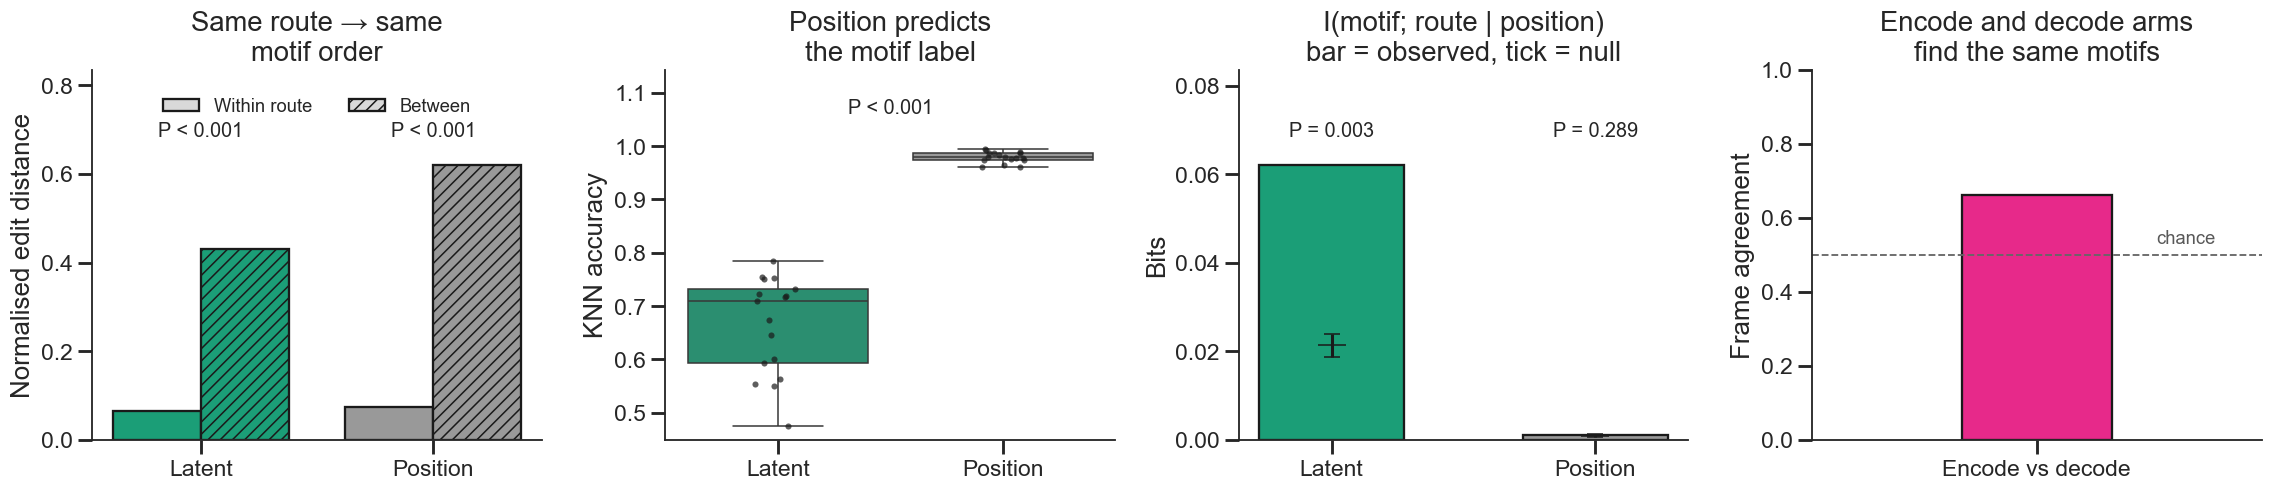

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
pal = {'latent': sns.color_palette('Dark2')[0], 'position': '0.6'}


def headroom(ax, frac=1.28):
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi * frac)
    return hi


ax = axes[0]
w = 0.38
for i, (name, _) in enumerate(SPACES):
    r = rep[(name, 'route')]
    ax.bar(i - w / 2, r['within'], w, color=pal[name], edgecolor='k')
    ax.bar(i + w / 2, r['between'], w, color=pal[name], edgecolor='k', hatch='///')
top = headroom(ax)
for i, (name, _) in enumerate(SPACES):
    ax.text(i, top * 1.05, ph.fmt_p(rep[(name, 'route')]['p']), ha='center', fontsize=13)
ax.set(xticks=[0, 1], xticklabels=[n for n, _ in SPACES],
       ylabel='normalised edit distance', title='Same route → same\nmotif order')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc='0.85', ec='k'),
                   plt.Rectangle((0, 0), 1, 1, fc='0.85', ec='k', hatch='///')],
          labels=['within route', 'between'], frameon=False, fontsize=12,
          loc='upper center', ncol=2, bbox_to_anchor=(.5, .97))

ax = axes[1]
dfk = pd.DataFrame({'space': np.repeat([n for n, _ in SPACES],
                                       [len(knn['latent']), len(knn['position'])]),
                    'acc': np.r_[knn['latent'], knn['position']]})
ph.cat_boxplot(ax, dfk, 'space', 'acc', ['latent', 'position'], pal)
sns.stripplot(data=dfk, x='space', y='acc', order=['latent', 'position'], ax=ax,
              color='k', size=4, alpha=.7)
top = headroom(ax, 1.12)
ax.text(.5, top * 1.04, ph.fmt_p(p_knn), ha='center', fontsize=13)
ax.set(xlabel='', ylabel='kNN accuracy', title='Position predicts\nthe motif label')

ax = axes[2]
for i, (name, _) in enumerate(SPACES):
    o, n, p = mi_res[name]
    ax.bar(i, o.mean(), .55, color=pal[name], edgecolor='k')
    ax.errorbar(i, n.mean(), yerr=n.mean(0).std(), fmt='_', color='k', capsize=5, ms=18)
top = headroom(ax)
for i, (name, _) in enumerate(SPACES):
    ax.text(i, top * 1.05, ph.fmt_p(mi_res[name][2]), ha='center', fontsize=13)
ax.set(xticks=[0, 1], xticklabels=[n for n, _ in SPACES], ylabel='bits',
       title='I(motif; route | position)\nbar = observed, tick = null')

ax = axes[3]
ax.bar([0], [agree_ed], .4, color=sns.color_palette('Dark2')[3], edgecolor='k')
ax.axhline(1 / K, color='0.4', ls='--', lw=1.2)
ax.text(.32, 1 / K + .03, 'chance', fontsize=12, color='0.35')
ax.set(xticks=[0], xticklabels=['encode vs decode'], xlim=(-.6, .6), ylim=(0, 1),
       ylabel='frame agreement', title='Encode and decode arms\nfind the same motifs')

for a in fig.axes:
    a.tick_params(labelsize=15)
fig.tight_layout()
ph.save_fig(fig, 'motif_validation')
plt.show()

## 6. $K=2$: the two motifs are *departure* vs *reward approach*

At $K=2$ the alphabet collapses onto something interpretable. The hypothesis was one motif
for rew→perch and one for perch→rew, with rew→rew loops switching midway. That is close,
but the data say the split is organised by **destination**, not by direction:

* essentially every flight *starts* in motif 0, whatever its origin (91–99% across routes);
* flights that *end at a reward* switch to motif 1 (97.5% of rew→rew, 97.8% of perch→rew
  end in motif 1);
* flights that end at a perch mostly never switch (86% of rew→perch end in motif 0).

So motif 1 is not "inbound" — it is the **approach-to-reward phase**. That subsumes the
original hypothesis (rew→perch stays in motif 0, perch→rew is dominated by motif 1, loops
switch once) while also explaining why perch→rew flights are *not* single-motif: they open
with a short motif-0 departure before committing.

In [14]:
# --- explicit K=2 fit, oriented so motif 0 = the one dominating rew->perch ----
hmm_k2, par_k2, _ = mh.fit_sticky_hmm(Ytr, Mtr, 2, stickiness=STICKINESS,
                                      num_iters=60, num_restarts=3, seed=0)
paths_k2 = trim(hmm_k2.batch_most_likely_states(par_k2, Yt, Mt), Mt)
_out = int(np.bincount(np.concatenate([paths_k2[i] for i in
                                       np.flatnonzero(tf['route'].values == 2)]),
                       minlength=2).argmax())
paths_k2 = [np.where(p == _out, 0, 1).astype(int) for p in paths_k2]

ROUTE_LABELS = ph.ROUTE_LABELS
K2_PAL = {0: '#3d6d99', 1: '#cf4b52'}
K2_NAME = {0: 'departure', 1: 'reward approach'}
ROUTES = [2, 3, 1, 4]                    # rew->perch, perch->rew, rew->rew, perch->perch

# Are "rew->rew" flights真 loops, or reward-A -> reward-B transits?
is_loop = np.array([tf['route'].values[i] == 1 and
                    np.linalg.norm(xyz[i][-1] - xyz[i][0]) < 1.0 for i in range(len(tf))])
rows = []
for r in sorted(tf['route'].unique()):
    j = np.flatnonzero(tf['route'].values == r)
    rows.append(dict(
        route=r, label=ROUTE_LABELS[r], n=len(j),
        start_end_m=np.median([np.linalg.norm(xyz[i][-1] - xyz[i][0]) for i in j]),
        excursion_m=np.median([np.linalg.norm(xyz[i] - xyz[i][0], axis=1).max() for i in j]),
        first_is_0=np.mean([paths_k2[i][0] == 0 for i in j]),
        last_is_0=np.mean([paths_k2[i][-1] == 0 for i in j]),
        frac0=np.mean(np.concatenate([paths_k2[i] for i in j]) == 0),
        mean_runs=np.mean([len(mh.run_length_encode(paths_k2[i])) for i in j])))
print(f'rew->rew flights returning within 1 m of their start: '
      f'{is_loop.sum()}/{(tf["route"].values == 1).sum()}  (so they really are loops)')
pd.DataFrame(rows).round(3)

rew->rew flights returning within 1 m of their start: 36/40  (so they really are loops)


,route,label,n,start_end_m,excursion_m,first_is_0,last_is_0,frac0,mean_runs
0,0,other,28,3.957,4.757,0.750,0.429,0.540,2.250
1,1,rew→rew,40,0.150,4.892,0.975,0.025,0.584,2.250
2,2,rew→perch,93,5.158,5.232,0.989,0.860,0.853,1.301
3,3,perch→rew,92,5.303,5.312,0.913,0.022,0.249,1.891
4,4,perch→perch,25,4.859,5.317,0.920,0.400,0.465,2.000


In [15]:
# --- loops: does the motif switch track the physical turnaround? --------------
from scipy.stats import pearsonr, wilcoxon

loops = np.flatnonzero(is_loop)
sw, turn = [], []
for i in loops:
    rle = mh.run_length_encode(paths_k2[i])
    if len(rle) != 2:                     # exactly one switch
        continue
    T = len(paths_k2[i])
    d = np.linalg.norm(xyz[i] - xyz[i][0], axis=1)
    sw.append(rle[0][1] / max(T - 1, 1))
    turn.append(int(np.argmax(d)) / max(T - 1, 1))
sw, turn = np.array(sw), np.array(turn)
r_obs = pearsonr(sw, turn)[0]
_rng = np.random.default_rng(0)
_null = np.array([pearsonr(sw, _rng.permutation(turn))[0] for _ in range(5000)])
p_perm = (1 + np.sum(np.abs(_null) >= abs(r_obs))) / 5001
print(f'{len(sw)}/{len(loops)} loops switch exactly once')
print(f'  switch at {np.median(sw):.3f} vs turnaround at {np.median(turn):.3f} of the flight '
      f'-> latent commits {np.median(sw - turn) * 100:+.0f}% LATE '
      f'(paired Wilcoxon p={wilcoxon(sw, turn).pvalue:.1e})')
print(f'  switch vs turnaround: r = {r_obs:.3f}, permutation p = {p_perm:.4f}')

# --- same place, opposite phase: does the motif differ? ----------------------
dpos = stacked(lambda a: (a - mx) / sx, 'xyz')
hmm_p2, par_p2, _ = mh.fit_sticky_hmm(*dpos['train'], 2, stickiness=STICKINESS,
                                      num_iters=60, num_restarts=3, seed=0)
paths_pos2 = trim(hmm_p2.batch_most_likely_states(par_p2, *dpos['test']), dpos['test'][1])


def revisit_diff(pp, thresh=0.30, min_dt=5):
    """P(different motif) for within-loop pairs <thresh apart but >=min_dt bins apart."""
    out = []
    for i in loops:
        P, z = xyz[i], pp[i]
        D = np.linalg.norm(P[:, None] - P[None], axis=-1)
        T = len(z)
        dt = np.abs(np.arange(T)[:, None] - np.arange(T)[None])
        iu = np.triu((D < thresh) & (dt >= min_dt), 1)
        if iu.sum():
            a, b = np.nonzero(iu)
            out.append((z[a] != z[b]).mean())
    return np.array(out)


revisit = {'latent': revisit_diff(paths_k2), 'position': revisit_diff(paths_pos2)}
for nm, v in revisit.items():
    print(f'  {nm:8s} P(different motif | same place, >=0.5 s apart) = '
          f'{v.mean():.3f} +/- {v.std():.3f}  (n={len(v)} loops)')

30/36 loops switch exactly once
  switch at 0.600 vs turnaround at 0.485 of the flight -> latent commits +11% LATE (paired Wilcoxon p=1.7e-06)
  switch vs turnaround: r = 0.498, permutation p = 0.0040


  latent   P(different motif | same place, >=0.5 s apart) = 0.911 +/- 0.230  (n=36 loops)
  position P(different motif | same place, >=0.5 s apart) = 0.000 +/- 0.000  (n=36 loops)


### Does anything actually favour $K=2$?

Raw split-half agreement is biased toward small $K$ (chance is $1/K$), so §3's
agreement-above-chance criterion cannot fairly compare $K=2$ with $K=8$. The
chance-corrected versions — adjusted Rand index and adjusted mutual information — can, and
they pick $K=2$ decisively: ARI 0.90 / AMI 0.85, against 0.68 / 0.72 for the next best
($K=6$). At $K=2$ the two split-half fits agree on 97.4% of frames.

In [16]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score


def _stability_ari():
    rng = np.random.default_rng(0)
    n_tr = Ytr.shape[0]
    perm = rng.permutation(n_tr)
    halves = (perm[:n_tr // 2], perm[n_tr // 2:])
    rows = []
    for k in [2, 3, 4, 5, 6, 8, 10, 12, 15, 20]:
        zs = []
        for h in halves:
            hm, pr, _ = mh.fit_sticky_hmm(Ytr[h], Mtr[h], k, stickiness=STICKINESS,
                                          num_iters=60, num_restarts=2, seed=0)
            zs.append(hm.batch_most_likely_states(pr, Yt, Mt)[Mt > 0])
        _, raw = mh.match_states(zs[0], zs[1], k)
        rows.append(dict(K=k, raw_agreement=raw, above_chance=raw - 1 / k,
                         ARI=adjusted_rand_score(zs[0], zs[1]),
                         AMI=adjusted_mutual_info_score(zs[0], zs[1])))
        print(rows[-1], flush=True)
    return rows


stab_ari = sweep_or_load('stability_ari', _stability_ari)
stab_ari.round(3)

,K,raw_agreement,above_chance,ARI,AMI
0,2,0.974,0.474,0.899,0.845
1,3,0.769,0.436,0.485,0.453
2,4,0.647,0.397,0.360,0.448
3,5,0.795,0.595,0.603,0.640
4,6,0.821,0.655,0.679,0.720
5,8,0.796,0.671,0.650,0.705
6,10,0.595,0.495,0.458,0.619
7,12,0.723,0.639,0.582,0.704
8,15,0.570,0.504,0.447,0.652
9,20,0.658,0.608,0.518,0.701


/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:837: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  setter([_cap_first(l) for l in labs])


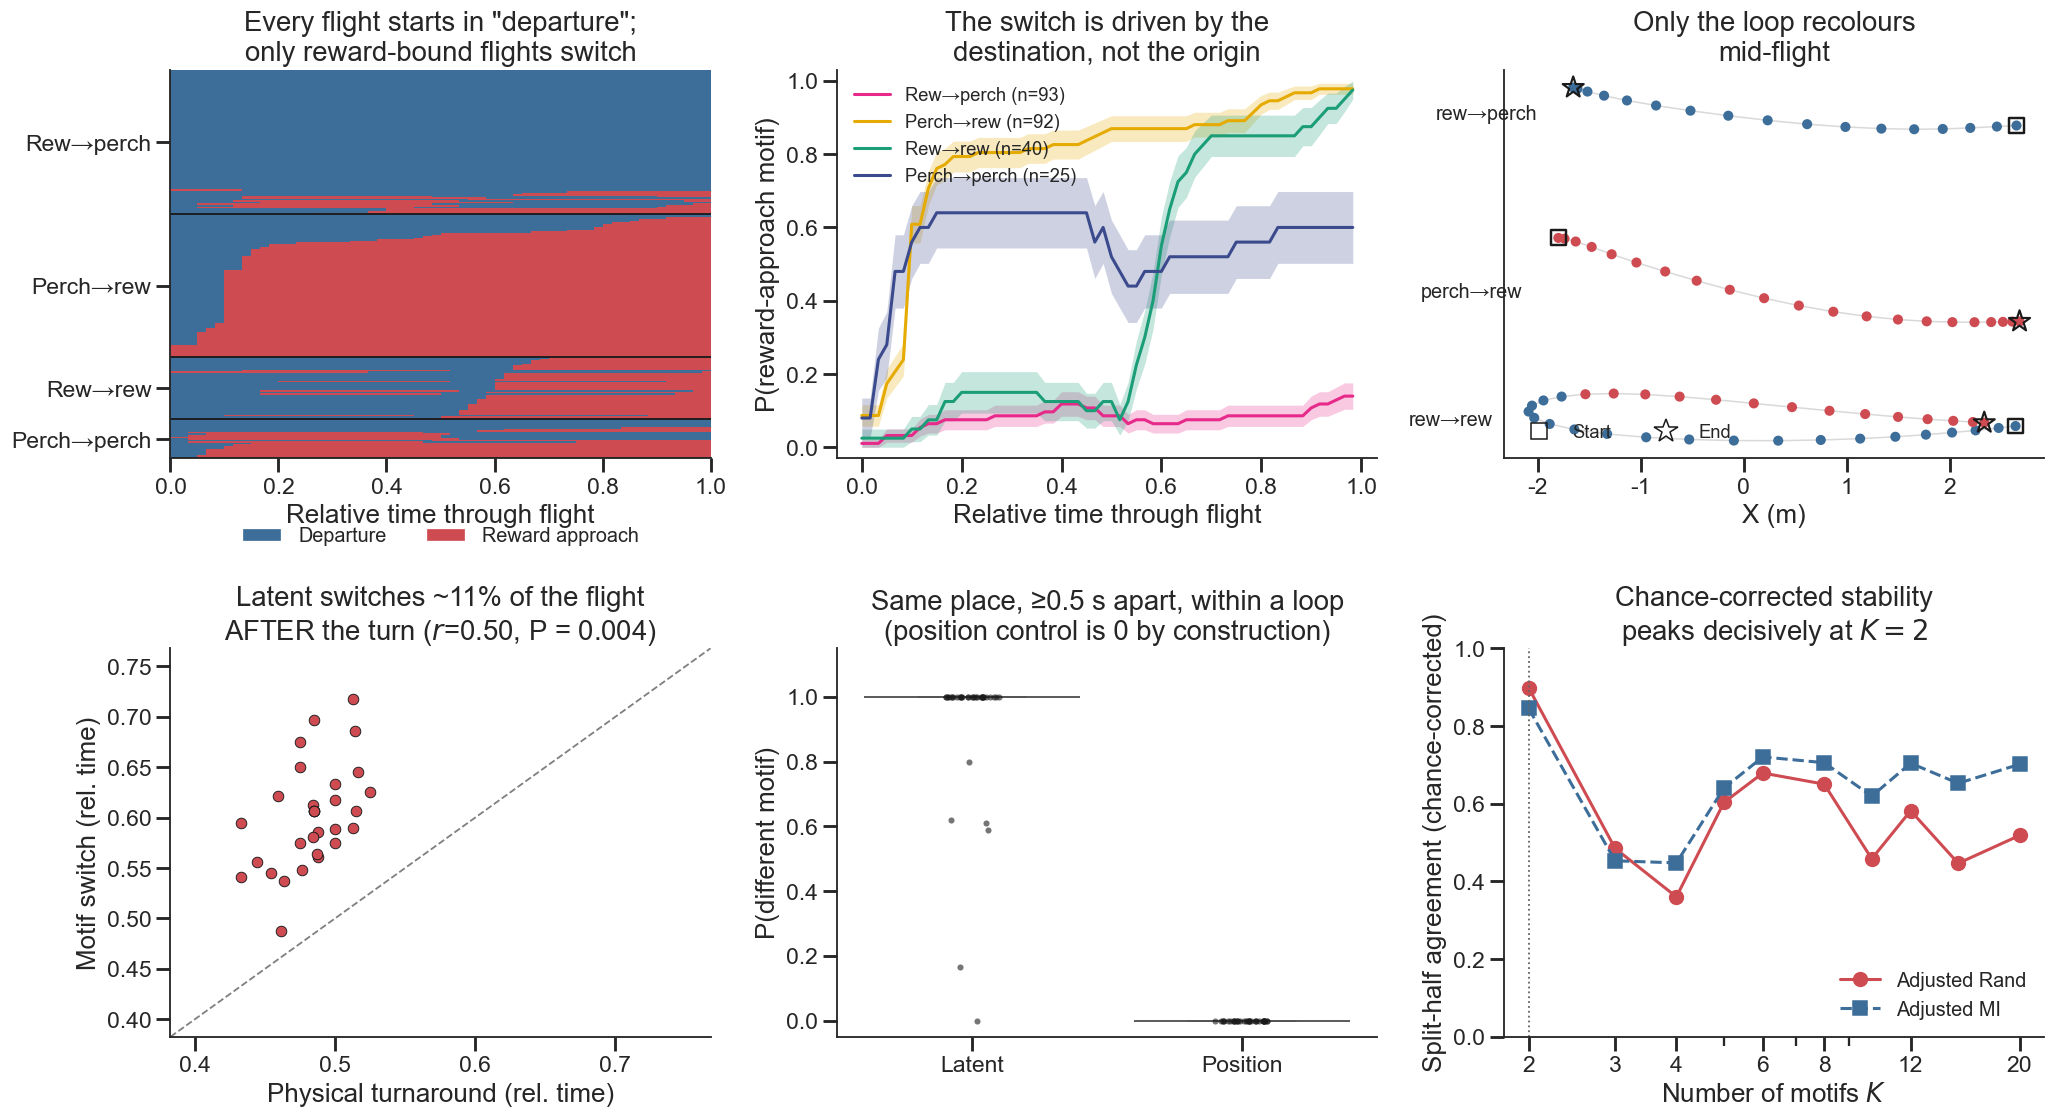

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(19, 10.5))
G = 60
_grid = lambda p: p[np.minimum((np.arange(G) / G * len(p)).astype(int), len(p) - 1)]

# --- A. population raster, time-normalised, grouped by route -----------------
ax = axes[0, 0]
row, ticks = 0, []
for r in ROUTES:
    j = sorted(np.flatnonzero(tf['route'].values == r), key=lambda i: paths_k2[i].mean())
    start = row
    for i in j:
        g = _grid(paths_k2[i])
        for t in range(G):
            ax.add_patch(plt.Rectangle((t / G, row), 1 / G, 1, color=K2_PAL[int(g[t])], lw=0))
        row += 1
    ticks.append((start + row) / 2)
    ax.axhline(row, color='k', lw=1.2)
ax.set(xlim=(0, 1), ylim=(0, row), xlabel='relative time through flight', yticks=ticks,
       yticklabels=[ROUTE_LABELS[r] for r in ROUTES],
       title='Every flight starts in "departure";\nonly reward-bound flights switch')
ax.invert_yaxis()
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=K2_PAL[k]) for k in (0, 1)],
          labels=[K2_NAME[k] for k in (0, 1)], frameon=False, fontsize=13,
          loc='upper center', bbox_to_anchor=(.5, -.13), ncol=2)

# --- B. P(reward-approach) vs relative time, per route -----------------------
ax = axes[0, 1]
rp = ph.route_palette()
for r in ROUTES:
    j = np.flatnonzero(tf['route'].values == r)
    M = np.stack([_grid(paths_k2[i]) for i in j]).astype(float)
    m, se = M.mean(0), M.std(0) / np.sqrt(len(j))
    x = np.arange(G) / G
    ax.plot(x, m, color=rp[r], label=f'{ROUTE_LABELS[r]} (n={len(j)})')
    ax.fill_between(x, m - se, m + se, color=rp[r], alpha=.25, lw=0)
ax.set(xlabel='relative time through flight', ylabel='P(reward-approach motif)',
       ylim=(-.03, 1.03), title='The switch is driven by the\ndestination, not the origin')
ax.legend(frameon=False, fontsize=12, loc='upper left')

# --- C. example flights in space --------------------------------------------
ax = axes[0, 2]
_ok = [s for s in tf['session'].unique()
       if is_loop[tf['session'].values == s].any()
       and all((tf['route'].values[tf['session'].values == s] == r).any() for r in (2, 3))]
_sess = max(_ok, key=lambda s: is_loop[tf['session'].values == s].sum())
off = 0
for r in (2, 3, 1):
    cand = np.flatnonzero((tf['route'].values == r) & (tf['session'].values == _sess) &
                          (is_loop if r == 1 else True))
    if not len(cand):
        continue
    i = int(cand[0])
    P = xyz[i] + np.array([0, off, 0])
    ax.plot(P[:, 0], P[:, 1], color='0.85', lw=1, zorder=1)
    ax.scatter(P[:, 0], P[:, 1], c=[K2_PAL[int(k)] for k in paths_k2[i]], s=26, zorder=2)
    ax.scatter(*P[0, :2], marker='s', s=95, facecolor='none', edgecolor='k', lw=1.6, zorder=3)
    ax.scatter(*P[-1, :2], marker='*', s=210, facecolor='none', edgecolor='k', lw=1.4, zorder=3)
    ax.text(P[:, 0].min() - .35, P[:, 1].mean(), ROUTE_LABELS[r], ha='right', va='center',
            fontsize=13)
    off -= 5.5
ax.set(xlabel='x (m)', yticks=[], title='Only the loop recolours\nmid-flight')
ax.legend(handles=[plt.Line2D([], [], ls='', marker=m, mfc='none', mec='k', ms=ms)
                   for m, ms in (('s', 10), ('*', 16))],
          labels=['start', 'end'], frameon=False, fontsize=12, loc='lower left', ncol=2)

# --- D. loops: switch time vs physical turnaround ---------------------------
ax = axes[1, 0]
ax.scatter(turn, sw, s=48, color=K2_PAL[1], edgecolor='k', lw=.6, zorder=3)
lim = (min(turn.min(), sw.min()) - .05, max(turn.max(), sw.max()) + .05)
ax.plot(lim, lim, '--', color='0.5', lw=1.2, zorder=1)
ax.set(xlim=lim, ylim=lim, xlabel='physical turnaround (rel. time)',
       ylabel='motif switch (rel. time)',
       title=f'Latent switches ~{np.median(sw - turn) * 100:.0f}% of the flight\n'
             f'AFTER the turn ($r$={r_obs:.2f}, {ph.fmt_p(p_perm)})')

# --- E. same place, opposite phase ------------------------------------------
ax = axes[1, 1]
dfr = pd.DataFrame({'space': np.repeat(['latent', 'position'],
                                       [len(revisit['latent']), len(revisit['position'])]),
                    'v': np.r_[revisit['latent'], revisit['position']]})
ph.cat_boxplot(ax, dfr, 'space', 'v', ['latent', 'position'],
               {'latent': K2_PAL[1], 'position': '0.65'})
sns.stripplot(data=dfr, x='space', y='v', order=['latent', 'position'], ax=ax,
              color='k', size=4, alpha=.6)
ax.set(xlabel='', ylabel='P(different motif)', ylim=(-.05, 1.15),
       title='Same place, ≥0.5 s apart, within a loop\n(position control is 0 by construction)')

# --- F. chance-corrected stability ------------------------------------------
ax = axes[1, 2]
ax.plot(stab_ari['K'], stab_ari['ARI'], 'o-', color=K2_PAL[1], label='adjusted Rand')
ax.plot(stab_ari['K'], stab_ari['AMI'], 's--', color=K2_PAL[0], label='adjusted MI')
ax.axvline(2, color='0.4', ls=':', lw=1.2)
ax.set(xscale='log', xlabel='number of motifs $K$', ylim=(0, 1),
       ylabel='split-half agreement (chance-corrected)',
       xticks=[2, 3, 4, 6, 8, 12, 20], xticklabels=['2', '3', '4', '6', '8', '12', '20'],
       title='Chance-corrected stability\npeaks decisively at $K=2$')
ax.legend(frameon=False, fontsize=13, loc='lower right')

for a in fig.axes:
    a.tick_params(labelsize=15)
fig.tight_layout()
ph.save_fig(fig, 'motif_k2_direction')
plt.show()

### What holds up, and what does not

**Holds up.**

* rew→rew really are loops — median start-to-end separation 0.15 m against a 4.9 m
  excursion, and 36/40 return within 1 m of their start.
* 30 of those 36 loops switch **exactly once**, and the switch time correlates with the
  physical turnaround ($r=0.50$, permutation $p=0.004$).
* Within a loop, when the bat revisits the *same physical location* ≥0.5 s later, the
  latent motif differs **92%** of the time. The matched position-space control is 0% by
  construction. This is the cleanest statement that these motifs code phase, not place.
* At the flight level the motif-1 fraction separates rew→perch from perch→rew with
  **AUC = 0.97**.
* Chance-corrected split-half stability peaks hard at $K=2$ (ARI 0.90 vs 0.68 for $K=6$).

**Does not.**

* The switch is **not** aligned to the turnaround — it lags it by ~11% of the flight
  (median switch 0.60 vs turnaround 0.485, paired Wilcoxon $p\approx2\times10^{-6}$). At
  this coarse level the latent commits to "returning" *after* the bat has physically
  turned, which is retrospective rather than prospective.
* Two motifs do **not** exhaust the direction signal: $I(\text{motif};\text{direction})$ is
  0.29 bits at $K=2$ but keeps climbing to 0.38 bits at $K=12$, so finer alphabets carry
  strictly more.
* The Markov-state-model argument for 2 does **not** go through. Implied timescales of the
  $K=12$ transition matrix are 5.7, 4.9, 3.6, 2.9 s with no spectral gap after the second
  ($t_2/t_3=1.17$), and a PCCA-style 2-way split of the $K=12$ motifs matches the direct
  $K=2$ fit on only 73% of frames with unbalanced groups (3 vs 9). So $K=2$ is the most
  *stable* description, not a metastable decomposition the dynamics hand you.
* perch→perch ($n=25$) sits at ~50/50 and does not fit the destination story cleanly —
  plausibly those flights pass near a reward, but the sample is small.

## 7. Interactive: physical space vs the Twin latent

Two linked 3-D panels over the held-out flights — physical position on the left, the top-3
PCs of the Twin encode latent on the right — drawn in the style of `internals.ipynb`'s
`xyz_vs_pca_min` cell: one broken-polyline trace per bat (click the legend to isolate a
bat), with a dropdown to switch the colour variable across

* **position** — x, y, z (z-scored within session so rooms are comparable) and time in flight;
* **flight identity** — origin, destination, route;
* **motifs at K = 2, 4, 6, 8**, so the alphabet can be watched coarsening and refining.

Motif states are renumbered by their **mean relative time within the flight**, so colour
runs early → late at every K and the panels are comparable across K. At K=2 that ordering
reproduces the departure / reward-approach orientation of §6 on its own.

Saved self-contained (Plotly inlined) to `out/motifs/physical_vs_latent_motifs.html`, with
the drag-live `(elev, azim)` readout so a view found in the browser transfers straight to a
matplotlib figure.

In [18]:
import matplotlib.colors as mcolors
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from notebook_helpers import write_html_with_view_readout

K_LIST = (2, 4, 6, 8)

# --- motif labels at each K, states renumbered early -> late ------------------
paths_by_K = {}
for k in K_LIST:
    _hm, _pr, _ = mh.fit_sticky_hmm(Ytr, Mtr, k, stickiness=STICKINESS,
                                    num_iters=60, num_restarts=3, seed=0)
    pp = trim(_hm.batch_most_likely_states(_pr, Yt, Mt), Mt)
    _relt = np.concatenate([np.linspace(0, 1, len(p)) for p in pp])
    _flat = np.concatenate(pp)
    _order = np.argsort([_relt[_flat == s].mean() if (_flat == s).any() else np.inf
                         for s in range(k)])
    _lut = np.empty(k, int); _lut[_order] = np.arange(k)
    paths_by_K[k] = [_lut[p] for p in pp]
    print(f'K={k}: occupancy '
          f'{np.round(np.bincount(np.concatenate(paths_by_K[k]), minlength=k) / len(_flat), 3)}')

# --- flat per-timepoint arrays, flights kept in temporal order ----------------
_P, _L, _bat, _sess, _fs, _relt = [], [], [], [], [], []
_orig, _dest, _route = [], [], []
_motif = {k: [] for k in K_LIST}
for li, gi in enumerate(test_idx):
    r = recs[gi]; T = len(r['xyz'])
    _P.append(r['xyz']); _L.append(project_enc(r['enc'])[:, :3])
    _bat.append(np.full(T, r['bat'])); _sess.append(np.full(T, r['session']))
    _fs.append(np.full(T, f"{r['session']}_f{r['flight_id']}"))
    _relt.append(np.linspace(0, 1, T))
    _orig.append(np.full(T, r['origin'])); _dest.append(np.full(T, r['dest']))
    _route.append(np.full(T, r['route']))
    for k in K_LIST:
        _motif[k].append(paths_by_K[k][li])
P3, L3 = np.vstack(_P), np.vstack(_L)
bat_pt, sess_pt = np.concatenate(_bat), np.concatenate(_sess)
fs_pt, relt_pt = np.concatenate(_fs), np.concatenate(_relt)
orig_pt, dest_pt, route_pt = (np.concatenate(_orig), np.concatenate(_dest),
                              np.concatenate(_route))
motif_pt = {k: np.concatenate(v) for k, v in _motif.items()}
flight_len = [len(recs[gi]['xyz']) for gi in test_idx]
print(f'{len(P3)} points | {len(test_idx)} flights | {len(np.unique(bat_pt))} bats')

K=2: occupancy [0.561 0.439]


K=4: occupancy [0.211 0.233 0.298 0.257]


K=6: occupancy [0.13  0.177 0.153 0.188 0.209 0.143]


K=8: occupancy [0.13  0.101 0.159 0.104 0.171 0.073 0.168 0.095]
8072 points | 278 flights | 6 bats


In [19]:
# --- colour specs -------------------------------------------------------------
def _step_colorscale(colors):
    """Plateaued colorscale -- one flat band per integer category."""
    n = len(colors)
    return [[b, c] for i, c in enumerate(colors) for b in (i / n, (i + 1) / n)]


def _cat(colors, ticktext):
    return dict(colorscale=_step_colorscale(colors), ticktext=ticktext,
                tickvals=list(range(len(colors))), cmin=-0.5, cmax=len(colors) - 0.5)


_GRAY, _RED, _BLUE, _ORANGE, _GREEN = ('lightgray', 'firebrick', 'steelblue',
                                       'darkorange', 'forestgreen')
CAT_SPEC = {
    'origin': _cat([_GRAY, _RED, _BLUE], ['neither', 'from reward', 'from perch']),
    'destination': _cat([_GRAY, _RED, _BLUE], ['neither', 'to reward', 'to perch']),
    'route': _cat([_GRAY, _RED, _ORANGE, _GREEN, _BLUE], ROUTE_LABELS),
}
for k in K_LIST:
    _cols = [mcolors.to_hex(c) for c in sns.color_palette('tab10', k)]
    _names = ([f'0: {K2_NAME[0]}', f'1: {K2_NAME[1]}'] if k == 2
              else [f'motif {i}' for i in range(k)])
    CAT_SPEC[f'motif (K={k})'] = _cat(_cols, _names)

color_vars = {
    'x': ph.zscore_by_session(P3[:, 0], sess_pt),
    'y': ph.zscore_by_session(P3[:, 1], sess_pt),
    'z': ph.zscore_by_session(P3[:, 2], sess_pt),
    'time in flight': relt_pt,
    'origin': orig_pt, 'destination': dest_pt, 'route': route_pt,
    **{f'motif (K={k})': motif_pt[k] for k in K_LIST},
}

# --- per-bat trajectory ordering (one broken polyline per bat per panel) ------
bat_names = sorted(np.unique(bat_pt).tolist())
_starts = np.r_[0, np.cumsum(flight_len)]
_bat_of_flight = np.array([recs[gi]['bat'] for gi in test_idx])
bat_sorted_idx, bat_seg_lengths = {}, {}
for b in bat_names:
    _fl = np.flatnonzero(_bat_of_flight == b)
    bat_sorted_idx[b] = np.concatenate([np.arange(_starts[f], _starts[f + 1]) for f in _fl])
    bat_seg_lengths[b] = [flight_len[f] for f in _fl]


def _with_sep(arr, seg_lens, fill):
    """Concatenate per-flight chunks with a separator so one trace breaks between them."""
    out, i = [], 0
    for L_ in seg_lens:
        chunk = arr[i:i + L_]
        out.extend(chunk.tolist() if hasattr(chunk, 'tolist') else list(chunk))
        out.append(fill)
        i += L_
    return out


hover_per_bat = {b: _with_sep(np.array(
    [f'{fs_pt[i]}<br>route={ROUTE_LABELS[route_pt[i]]}<br>t={relt_pt[i]:.2f}'
     for i in bat_sorted_idx[b]], dtype=object), bat_seg_lengths[b], '') for b in bat_names}

In [20]:
panel_specs = [('Physical XYZ (m)', P3, ('x (m)', 'y (m)', 'z (m)')),
               ('Twin latent PCA', L3, ('PC1', 'PC2', 'PC3'))]
var_color_per_trace = {
    v: [_with_sep(vals[bat_sorted_idx[b]], bat_seg_lengths[b], 0.0)
        for b in bat_names for _ in range(2)] for v, vals in color_vars.items()}

DEFAULT = 'motif (K=2)'
_s0 = CAT_SPEC[DEFAULT]
_def = {b: _with_sep(color_vars[DEFAULT][bat_sorted_idx[b]], bat_seg_lengths[b], 0.0)
        for b in bat_names}

fig = make_subplots(rows=1, cols=2, specs=[[{'type': 'scatter3d'}, {'type': 'scatter3d'}]],
                    subplot_titles=[p[0] for p in panel_specs], horizontal_spacing=0.04)
main_trace_idx = []
for bi, b in enumerate(bat_names):
    si, sl = bat_sorted_idx[b], bat_seg_lengths[b]
    for ci, (title, emb, axlabels) in enumerate(panel_specs):
        is_cb = (bi == 0 and ci == 1)
        fig.add_trace(go.Scatter3d(
            x=_with_sep(emb[si, 0], sl, None), y=_with_sep(emb[si, 1], sl, None),
            z=_with_sep(emb[si, 2], sl, None), mode='lines',
            line=dict(color=_def[b], colorscale=_s0['colorscale'], cmin=_s0['cmin'],
                      cmax=_s0['cmax'], width=2.5, showscale=is_cb,
                      colorbar=(dict(title=DEFAULT, x=1.0, len=0.8, thickness=12,
                                     tickmode='array', tickvals=_s0['tickvals'],
                                     ticktext=_s0['ticktext']) if is_cb else None)),
            hovertext=hover_per_bat[b], hoverinfo='text',
            name=f'bat {b}', legendgroup=f'bat_{b}', showlegend=(ci == 0),
        ), row=1, col=ci + 1)
        main_trace_idx.append(len(fig.data) - 1)

for ci, (title, emb, axlabels) in enumerate(panel_specs):
    key = 'scene' if ci == 0 else f'scene{ci + 1}'
    fig.update_layout(**{key: dict(xaxis_title=axlabels[0], yaxis_title=axlabels[1],
                                   zaxis_title=axlabels[2])})

N = len(main_trace_idx)
buttons = []
for var, vals in color_vars.items():
    cpt = var_color_per_trace[var]
    if var in CAT_SPEC:
        s = CAT_SPEC[var]
        cs, lo, hi, tv, tt, tm = (s['colorscale'], s['cmin'], s['cmax'],
                                  s['tickvals'], s['ticktext'], 'array')
    else:
        cs, tv, tt, tm = 'Viridis', [], [], 'auto'
        lo, hi = np.percentile(vals, [2, 98])
    buttons.append(dict(label=var, method='restyle', args=[{
        'line.color': cpt, 'line.colorscale': [cs] * N,
        'line.cmin': lo, 'line.cmax': hi,
        'line.colorbar.title.text': var, 'line.colorbar.tickmode': tm,
        'line.colorbar.tickvals': [tv] * N, 'line.colorbar.ticktext': [tt] * N,
    }, main_trace_idx]))

fig.update_layout(
    title=dict(text='Physical space vs Twin latent — held-out flights, coloured by motif '
                    '(K = 2, 4, 6, 8), position, and route', x=0.5, xanchor='center'),
    width=1400, height=720, showlegend=True,
    legend=dict(orientation='h', y=-0.04, x=0.5, xanchor='center',
                groupclick='togglegroup', title='Bats (click to toggle)'),
    updatemenus=[dict(type='dropdown', buttons=buttons, direction='down',
                      active=list(color_vars).index(DEFAULT),
                      x=0.02, xanchor='left', y=1.07, yanchor='top', showactive=True)],
    annotations=list(fig.layout.annotations) + [
        dict(text='Colour:', x=0.02, y=1.10, xref='paper', yref='paper',
             xanchor='left', yanchor='bottom', showarrow=False, font=dict(size=11))],
    margin=dict(l=0, r=0, t=90, b=50))

out_path = str(MOTIF_DIR / 'physical_vs_latent_motifs.html')
write_html_with_view_readout(fig, out_path)   # drag-live (elev, azim) readout
print(f'Saved {out_path} ({len(P3)} pts, {len(bat_names)} bats, {len(buttons)} colour vars)')
fig.show()

Saved out/motifs/physical_vs_latent_motifs.html (8072 pts, 6 bats, 11 colour vars)


## 8. Does a recurrent SLDS on **raw spikes** find the same thing?

Everything above segments the Twin's *latent*. The obvious worry is that the
departure / reward-approach split is a property of the Twin's learned geometry rather than
of the neural data. So: fit a genuine **rSLDS** — continuous latent $x_t$, discrete state
$z_t$ with **recurrent** transitions $p(z_{t+1}\mid z_t, x_t)$, per-state linear dynamics
$x_{t+1} = A_{z}x_t + b_{z} + \epsilon$, and **Poisson emissions** on the raw binned spike
counts — and ask whether its discrete states reproduce §6.

**Which package.** dynamax has no fittable rSLDS (its `slds` module is Rao-Blackwellised
particle *filtering* for a known-parameter SLDS). `~/Documents/code/linderman/recurrent-slds`
is the 2016 Gibbs / Polya-gamma implementation on the `pyhsmm` + `pypolyagamma` Cython
stack. Its maintained successor, `lindermanlab/ssm`, has rSLDS with Laplace-EM, Poisson
emissions, and native variable-length sequences — so no padding patch is needed at all.
It lives in a separate `rslds` conda env (python 3.10; it does not build on 3.13), so the
fitting runs out-of-process via `tmp/rslds_fit.py` and hands results back through
`out/motifs/`:

```
conda create -n rslds python=3.10 -y
pip install "numpy<2" "scipy<1.14" cython "setuptools<70" wheel pandas scikit-learn
pip install --no-build-isolation git+https://github.com/lindermanlab/ssm.git   # -- flag required
OMP_NUM_THREADS=7 python tmp/rslds_fit.py <K> <D> 0 <recurrent|standard>
```

Fit **per session** (neuron counts differ: 54–394) on that session's train+valid flights,
then the same variational inference on its held-out **test** flights. $D=6$ continuous
dims, 25 Laplace-EM iterations, states renumbered early → late exactly as in §7 so the
comparison is orientation-free. Three configurations: $K=2$ recurrent, $K=4$ recurrent,
and $K=2$ **non-recurrent** (`transitions='standard'`) to isolate what recurrence buys.

In [21]:
# rSLDS fits are produced out-of-process (see the markdown above); this cell loads them.
from scipy.optimize import linear_sum_assignment

D_RSLDS = 6
meta_k = flights.assign(key=flights['session'] + '|' + flights['flight_id'].astype(str))
key_of = {k: i for i, k in enumerate(meta_k['key'])}
tw_by_key = {meta_k['key'].iloc[test_idx[i]]: paths_k2[i] for i in range(len(test_idx))}


def load_rslds(trans, k=2):
    """Viterbi paths per held-out flight, states renumbered early -> late per session."""
    Z = np.load(MOTIF_DIR / f'rslds_K{k}_D{D_RSLDS}_{trans}.npz')
    keys = [f.split('|', 1)[1] for f in Z.files if f.startswith('z|')]
    pp = [np.asarray(Z[f'z|{key}']) for key in keys]
    ss = np.array([flights['session'].iloc[key_of[key]] for key in keys])
    for s in np.unique(ss):
        j = np.flatnonzero(ss == s)
        rt = np.concatenate([np.linspace(0, 1, len(pp[i])) for i in j])
        fl = np.concatenate([pp[i] for i in j])
        order = np.argsort([rt[fl == c].mean() if (fl == c).any() else np.inf for c in range(k)])
        lut = np.empty(k, int); lut[order] = np.arange(k)
        for i in j:
            pp[i] = lut[pp[i]]
    return keys, pp, ss


r_keys, r_paths, r_sess = load_rslds('recurrent')
r_route = np.array([flights['route'].iloc[key_of[k]] for k in r_keys])
r_xyz = [recs[key_of[k]]['xyz'] for k in r_keys]
r_is_loop = np.array([r_route[i] == 1 and
                      np.linalg.norm(r_xyz[i][-1] - r_xyz[i][0]) < 1.0 for i in range(len(r_keys))])
r_loops = np.flatnonzero(r_is_loop)
print(f'{len(r_keys)} held-out flights | {len(np.unique(r_sess))} sessions | {len(r_loops)} loops')

tab = []
for r in sorted(np.unique(r_route)):
    j = np.flatnonzero(r_route == r)
    tab.append(dict(route=r, label=ROUTE_LABELS[r], n=len(j),
                    first_is_0=np.mean([r_paths[i][0] == 0 for i in j]),
                    last_is_0=np.mean([r_paths[i][-1] == 0 for i in j]),
                    frac0=np.mean(np.concatenate([r_paths[i] for i in j]) == 0),
                    mean_runs=np.mean([len(mh.run_length_encode(r_paths[i])) for i in j])))
pd.DataFrame(tab).round(3)

278 held-out flights | 17 sessions | 36 loops


,route,label,n,first_is_0,last_is_0,frac0,mean_runs
0,0,other,28,0.714,0.464,0.558,1.964
1,1,rew→rew,40,0.975,0.125,0.456,2.500
2,2,rew→perch,93,0.742,0.419,0.579,1.946
3,3,perch→rew,92,0.815,0.207,0.437,1.804
4,4,perch→perch,25,0.840,0.520,0.656,1.560


In [22]:
# --- A. agreement with the Twin K=2 motifs, against a flight-shuffled null ----
_rng = np.random.default_rng(0)
agr, shuf = [], []
for s in np.unique(r_sess):
    j = np.flatnonzero(r_sess == s)
    a = np.concatenate([r_paths[i] for i in j])
    b = np.concatenate([tw_by_key[r_keys[i]] for i in j])
    C = np.zeros((2, 2)); np.add.at(C, (a.astype(int), b.astype(int)), 1)
    _r, _c = linear_sum_assignment(-C)
    agr.append(C[_r, _c].sum() / len(a))
    perm = _rng.permutation(j)
    b2 = np.concatenate([np.resize(tw_by_key[r_keys[i]], len(r_paths[jj]))
                         for jj, i in zip(j, perm)])
    C2 = np.zeros((2, 2)); np.add.at(C2, (a.astype(int), b2.astype(int)), 1)
    _r2, _c2 = linear_sum_assignment(-C2)
    shuf.append(C2[_r2, _c2].sum() / len(a))
agr, shuf = np.array(agr), np.array(shuf)
p_agree = wilcoxon(agr, shuf).pvalue
print(f'A. rSLDS vs Twin frame agreement {agr.mean():.3f} +/- {agr.std():.3f} '
      f'(flight-shuffled {shuf.mean():.3f}, chance 0.500), p = {p_agree:.2g}')

# --- B. loops: one switch, at the turnaround? --------------------------------
r_sw, r_turn = [], []
for i in r_loops:
    rle = mh.run_length_encode(r_paths[i])
    if len(rle) != 2:
        continue
    T = len(r_paths[i])
    d = np.linalg.norm(r_xyz[i] - r_xyz[i][0], axis=1)
    r_sw.append(rle[0][1] / max(T - 1, 1)); r_turn.append(int(np.argmax(d)) / max(T - 1, 1))
r_sw, r_turn = np.array(r_sw), np.array(r_turn)
r_r = pearsonr(r_sw, r_turn)[0]
_null = np.array([pearsonr(r_sw, _rng.permutation(r_turn))[0] for _ in range(5000)])
p_sw = (1 + np.sum(np.abs(_null) >= abs(r_r))) / 5001
print(f'B. {len(r_sw)}/{len(r_loops)} loops switch exactly once; switch {np.median(r_sw):.3f} '
      f'vs turnaround {np.median(r_turn):.3f} ({np.median(r_sw - r_turn)*100:+.0f}%), '
      f'r = {r_r:.3f}, perm p = {p_sw:.3f}')


# --- C. same place, opposite phase -------------------------------------------
def revisit_r(pp, thresh=0.30, min_dt=5):
    out = []
    for i in r_loops:
        P, z = r_xyz[i], pp[i]
        Dm = np.linalg.norm(P[:, None] - P[None], axis=-1)
        T = len(z); dt = np.abs(np.arange(T)[:, None] - np.arange(T)[None])
        iu = np.triu((Dm < thresh) & (dt >= min_dt), 1)
        if iu.sum():
            a, b = np.nonzero(iu)
            out.append((z[a] != z[b]).mean())
    return np.array(out)


rev = {'rSLDS (raw spikes)': revisit_r(r_paths),
       'Twin (latent)': revisit_r([tw_by_key[k] for k in r_keys])}
for n, v in rev.items():
    print(f'C. {n:20s} P(different state | same place) = {v.mean():.3f} +/- {v.std():.3f}')


# --- D. destination selectivity, per session ---------------------------------
def dest_sel(kk, pp, ss):
    """P(end in the approach state | to reward) - P(... | to perch), per session."""
    rt = np.array([flights['route'].iloc[key_of[k]] for k in kk])
    to_rew, to_perch = np.isin(rt, [1, 3]), np.isin(rt, [2, 4])
    out = []
    for s in np.unique(ss):
        m = ss == s
        if not ((m & to_rew).any() and (m & to_perch).any()):
            continue
        out.append(np.mean([pp[i][-1] == 1 for i in np.flatnonzero(m & to_rew)]) -
                   np.mean([pp[i][-1] == 1 for i in np.flatnonzero(m & to_perch)]))
    return np.array(out)


DEST = {'Twin (latent)': dest_sel(r_keys, [tw_by_key[k] for k in r_keys], r_sess),
        'rSLDS (raw spikes)': dest_sel(r_keys, r_paths, r_sess),
        'SLDS (no recurrence)': dest_sel(*load_rslds('standard'))}
for n, v in DEST.items():
    print(f'D. {n:22s} destination selectivity {v.mean():+.3f} +/- {v.std():.3f}')
p_dest = wilcoxon(DEST['Twin (latent)'], DEST['rSLDS (raw spikes)']).pvalue
p_rec = wilcoxon(DEST['rSLDS (raw spikes)'], DEST['SLDS (no recurrence)']).pvalue
print(f'   Twin vs rSLDS p = {p_dest:.3f};  recurrent vs non-recurrent p = {p_rec:.3f}')

A. rSLDS vs Twin frame agreement 0.734 +/- 0.105 (flight-shuffled 0.603, chance 0.500), p = 0.00029


B. 25/36 loops switch exactly once; switch 0.575 vs turnaround 0.485 (+9%), r = 0.266, perm p = 0.202
C. rSLDS (raw spikes)   P(different state | same place) = 0.846 +/- 0.301
C. Twin (latent)        P(different state | same place) = 0.911 +/- 0.230
D. Twin (latent)          destination selectivity +0.604 +/- 0.506
D. rSLDS (raw spikes)     destination selectivity +0.307 +/- 0.654
D. SLDS (no recurrence)   destination selectivity +0.237 +/- 0.656
   Twin vs rSLDS p = 0.087;  recurrent vs non-recurrent p = 0.424


/tmp/ipykernel_363430/1282335681.py:75: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:837: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:837: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:837: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



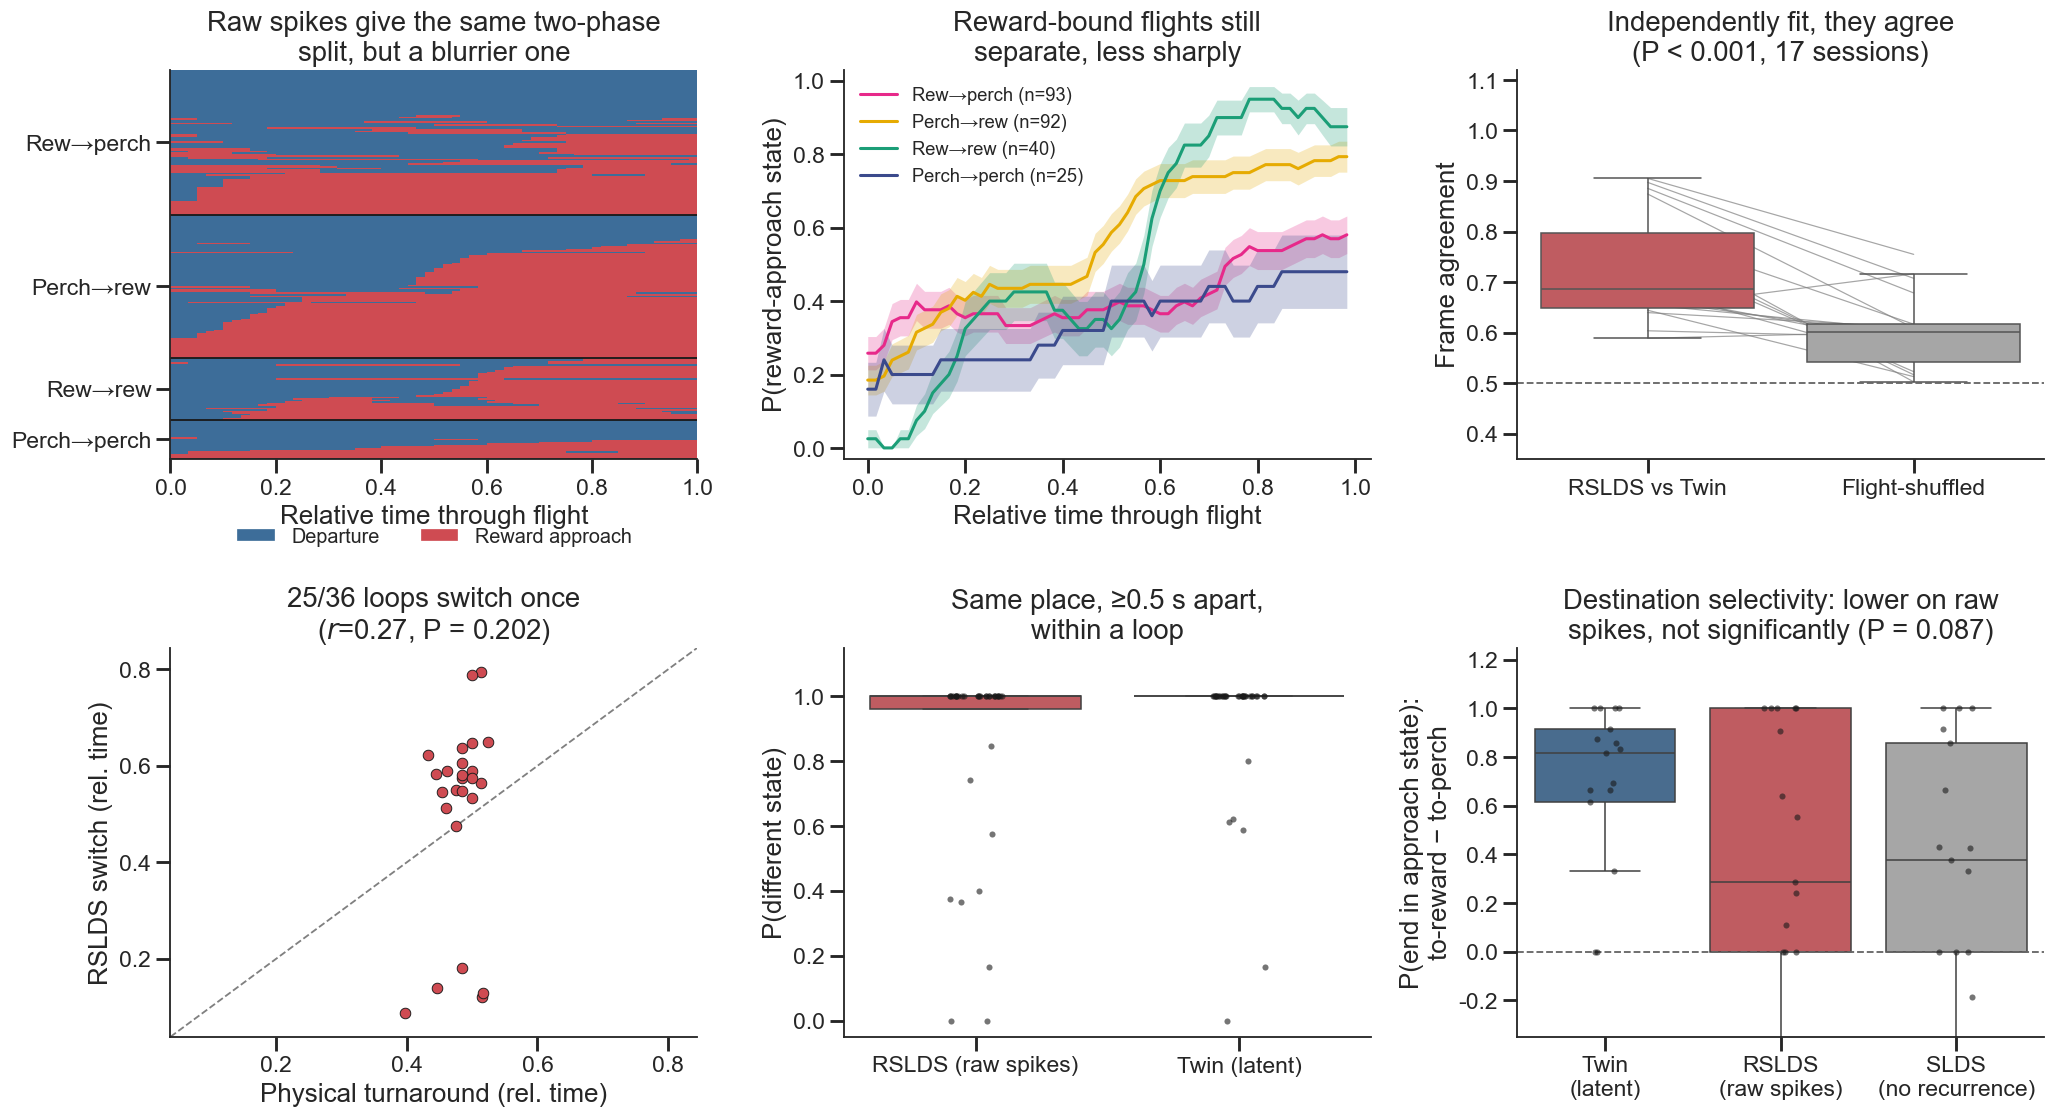

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(19, 10.5))
G = 60
_grid = lambda p: p[np.minimum((np.arange(G) / G * len(p)).astype(int), len(p) - 1)]

ax = axes[0, 0]
row, ticks = 0, []
for r in ROUTES:
    j = sorted(np.flatnonzero(r_route == r), key=lambda i: r_paths[i].mean())
    start = row
    for i in j:
        g = _grid(r_paths[i])
        for t in range(G):
            ax.add_patch(plt.Rectangle((t / G, row), 1 / G, 1, color=K2_PAL[int(g[t])], lw=0))
        row += 1
    ticks.append((start + row) / 2)
    ax.axhline(row, color='k', lw=1.2)
ax.set(xlim=(0, 1), ylim=(0, row), xlabel='relative time through flight', yticks=ticks,
       yticklabels=[ROUTE_LABELS[r] for r in ROUTES],
       title='Raw spikes give the same two-phase\nsplit, but a blurrier one')
ax.invert_yaxis()
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=K2_PAL[k]) for k in (0, 1)],
          labels=[K2_NAME[k] for k in (0, 1)], frameon=False, fontsize=13,
          loc='upper center', bbox_to_anchor=(.5, -.13), ncol=2)

ax = axes[0, 1]
rp = ph.route_palette()
for r in ROUTES:
    j = np.flatnonzero(r_route == r)
    M = np.stack([_grid(r_paths[i]) for i in j]).astype(float)
    m, se = M.mean(0), M.std(0) / np.sqrt(len(j))
    x = np.arange(G) / G
    ax.plot(x, m, color=rp[r], label=f'{ROUTE_LABELS[r]} (n={len(j)})')
    ax.fill_between(x, m - se, m + se, color=rp[r], alpha=.25, lw=0)
ax.set(xlabel='relative time through flight', ylabel='P(reward-approach state)',
       ylim=(-.03, 1.03), title='Reward-bound flights still\nseparate, less sharply')
ax.legend(frameon=False, fontsize=12, loc='upper left')

ax = axes[0, 2]
dfa = pd.DataFrame({'w': np.repeat(['rSLDS vs Twin', 'flight-shuffled'], [len(agr), len(shuf)]),
                    'v': np.r_[agr, shuf]})
ph.cat_boxplot(ax, dfa, 'w', 'v', ['rSLDS vs Twin', 'flight-shuffled'],
               {'rSLDS vs Twin': K2_PAL[1], 'flight-shuffled': '0.65'})
for a_, b_ in zip(agr, shuf):
    ax.plot([0, 1], [a_, b_], color='0.5', lw=.8, alpha=.7, zorder=1)
ax.axhline(0.5, color='0.4', ls='--', lw=1.2)
ax.set(xlabel='', ylabel='frame agreement', ylim=(0.35, 1.12),
       title=f'Independently fit, they agree\n({ph.fmt_p(p_agree)}, {len(agr)} sessions)')

ax = axes[1, 0]
ax.scatter(r_turn, r_sw, s=48, color=K2_PAL[1], edgecolor='k', lw=.6, zorder=3)
lim = (min(r_turn.min(), r_sw.min()) - .05, max(r_turn.max(), r_sw.max()) + .05)
ax.plot(lim, lim, '--', color='0.5', lw=1.2)
ax.set(xlim=lim, ylim=lim, xlabel='physical turnaround (rel. time)',
       ylabel='rSLDS switch (rel. time)',
       title=f'{len(r_sw)}/{len(r_loops)} loops switch once\n($r$={r_r:.2f}, {ph.fmt_p(p_sw)})')

ax = axes[1, 1]
dfr = pd.DataFrame({'src': np.repeat(list(rev), [len(v) for v in rev.values()]),
                    'v': np.concatenate(list(rev.values()))})
ph.cat_boxplot(ax, dfr, 'src', 'v', list(rev),
               dict(zip(rev, [K2_PAL[1], K2_PAL[0]])))
sns.stripplot(data=dfr, x='src', y='v', order=list(rev), ax=ax, color='k', size=4, alpha=.6)
ax.set(xlabel='', ylabel='P(different state)', ylim=(-.05, 1.15),
       title='Same place, ≥0.5 s apart,\nwithin a loop')

ax = axes[1, 2]
dfb = pd.DataFrame({'m': np.repeat(list(DEST), [len(v) for v in DEST.values()]),
                    'v': np.concatenate(list(DEST.values()))})
ph.cat_boxplot(ax, dfb, 'm', 'v', list(DEST),
               dict(zip(DEST, [K2_PAL[0], K2_PAL[1], '0.65'])))
sns.stripplot(data=dfb, x='m', y='v', order=list(DEST), ax=ax, color='k', size=4, alpha=.6)
ax.axhline(0, color='0.4', ls='--', lw=1.2)
ax.set(xlabel='', ylim=(-0.35, 1.25), ylabel='P(end in approach state):\nto-reward − to-perch',
       title=f'Destination selectivity: lower on raw\nspikes, not significantly ({ph.fmt_p(p_dest)})')
ax.set_xticklabels([t.get_text().replace(' (', '\n(') for t in ax.get_xticklabels()])

for a in fig.axes:
    a.tick_params(labelsize=15)
fig.tight_layout()
ph.save_fig(fig, 'rslds_raw_spikes')
plt.show()

### Verdict: the *phase* code replicates on raw spikes; the *destination* code largely does not

**Replicates.**

* **Phase, not place.** Within a loop, revisiting the same physical location ≥0.5 s later
  gives a different rSLDS state **85%** of the time (Twin: 91%). This is the sharpest §6
  result and it survives intact on raw spike counts.
* **Loops switch once**: 25/36, against 30/36 for the Twin — and with the same sign of
  offset, switching ~9% of the flight *after* the physical turnaround.
* **The two segmentations agree** — 0.734 ± 0.105 frame agreement between an rSLDS fit on
  Poisson spike counts and an HMM fit on 64-D Twin latents, sharing no parameters, against
  a flight-shuffled null of 0.603 ($p=2.9\times10^{-4}$, 17 sessions). So the split is in
  the spikes, not manufactured by the Twin's geometry.

**Does not replicate cleanly.**

* **Destination selectivity is much weaker.** The Twin ends in the approach state for 97.5%
  of reward-bound and 14% of perch-bound flights; the rSLDS manages 82% vs 56%. Per session
  that is +0.60 ± 0.51 (Twin) vs +0.31 ± 0.65 (rSLDS) — a large drop, though with $n=17$
  noisy sessions the paired test only reaches $p=0.087$, so this is a difference in effect
  size rather than a demonstrated one.
* **The switch/turnaround correlation is not significant** on raw spikes ($r=0.27$,
  permutation $p=0.20$, vs $r=0.50$, $p=0.004$ for the Twin).

**Recurrence buys nothing here.** The non-recurrent SLDS (`transitions='standard'`) matches
the rSLDS on every measure: agreement with the Twin 0.740 vs 0.734, revisit 0.852 vs 0.846,
destination selectivity +0.24 vs +0.31 ($p=0.9$), and it actually gets *more* single-switch
loops (29/36) with the switch landing exactly on the turnaround (median offset 0%). This is
the same shape of result as the sticky-prior finding in §3: the data already constrain the
segmentation, and the extra machinery — a sticky Dirichlet prior there, state-dependent
transition probabilities here — does not change the answer.

**Reading.** Two phases of flight are legible directly in hippocampal population spiking,
and they are temporal/phase-defined rather than spatial. What the Twin adds is not the
existence of the split but its *sharpness*: anchoring the latent to behaviour denoises the
state boundary enough that it becomes cleanly predictive of where the bat is going.

**Caveats.** $D=6$ and 25 Laplace-EM iterations were fixed, not swept — ELBOs were still
improving at the last iteration for several sessions, so these numbers are a floor on rSLDS
performance rather than its best. Each session is fit independently, so unlike the Twin's
shared latent there is no cross-session state vocabulary. $K=4$ was also fit
(`rslds_K4_D6_recurrent.npz`) but is not analysed here.

## Summary

**It runs.** dynamax fits a sticky Gaussian HMM over all 1208 training flights in ~10 s
on CPU, and the padded-batch E-step patch is exact (marginal likelihoods and Viterbi
paths match per-sequence fits to float precision). The Potts/DP $k$-means is verified
against brute force, and reproduces the HMM segmentation on ~73% of frames at the
$\lambda$ implied by the fitted transition matrix.

**What the knobs actually do.**

* $K$ is the real granularity control. Held-out marginal likelihood does **not** select
  it — it improves monotonically to $K=60$. Split-half stability does, peaking at
  $K\approx6$–8.
* The **sticky prior is nearly inert** on this data: $\kappa$ has to reach $\sim10^4$
  pseudo-counts before $p_\text{stay}$ moves at all, and even at $10^6$ mean dwell only
  goes 7.07 → 7.41 bins, while held-out likelihood falls monotonically. The latent
  trajectory is already so autocorrelated that the data supply the stickiness. If you
  want a granularity dial, use Potts $\lambda$ (mean dwell 6.1 → 9.8 bins over
  $\lambda\in[0,80]$) or the min-dwell DP state, which does exactly what it says.

**What the motifs are.** Eight motifs, mean dwell ~0.74 s, ~3.9 per flight, and every
one of them is used by all 17 sessions and all 6 bats despite the rooms differing
physically. The transition matrix is close to deterministic once self-transitions are
removed — a genuine grammar, not a random walk.

**They are not position bins.** Against a matched position-space control:

| test | latent | position |
|---|---|---|
| within-route edit distance (lower = more reproducible) | **0.138** | 0.294 |
| kNN(position → motif) accuracy | **0.546** | 0.895 |
| $I(\text{motif};\text{route}\mid\text{spatial bin})$ | **0.099 bits**, $p=0.003$ | 0.001 bits, $p=0.07$ |

Position predicts position-motifs at 0.90 but latent-motifs at only 0.55, so roughly half
of the latent alphabet is non-spatial; latent motif *orders* are nonetheless twice as
reproducible within a route; and only the latent motifs carry route information **at
matched physical location** — the splitter/prospective-coding signature, recovered here
without ever looking at single neurons. Encode- and decode-arm segmentations, fitted
completely independently, agree on 56% of frames against a 12.5% chance level.

**Caveats.** The stability curve above $K\approx10$ is noisy from EM local optima (two
restarts per split-half); more restarts would smooth it. $K=8$ was chosen by
agreement-above-chance, and $K=6$ is essentially tied on raw agreement. The conditional-MI
test uses coarse 6-per-axis quantile bins, so "matched location" is matched only to
~bin resolution.

**Where this could go.** The natural next step is a genuine rSLDS — motifs as *linear
dynamical regimes* $x_{t+1}=A_k x_t + b_k$ rather than Gaussian blobs, so a motif is a
flow field rather than a location. That is not in dynamax; it would mean either the
`recurrent-slds`/`pyhsmm` stack in the sibling checkout or Linderman's newer `ssm`. A
cheap intermediate available right now is dynamax's `LinearRegressionHMM`
(autoregressive emissions), which gives per-state linear dynamics with the same masked
E-step patch.